# LIFE-seq Figure 6, Extended Data Figures 3–4 and Supplementary Figure S11

English: Spatial transcriptomic analysis of injury-associated expression, cell-class RNA contributions and coexpression modules. This notebook combines RCTD/C-SIDE visualizations, gene-level spatial statistics and M02 module analyses. Shared ten-capture maps are displayed once. See [README](README.md) for inputs, methods and panel mapping.

中文：分析损伤相关表达、细胞类别RNA贡献及共表达模块，包含RCTD/C-SIDE可视化、基因空间统计和M02模块分析。正文与扩展图共用的十样本空间图统一展示，输入、方法和图版对应见README。


[Repository overview](../README.md) · [Figure guide](README.md)

中文：运行范围、输入布局和数据说明见上述文档。

## Setup and input data / 环境与输入

English: Run the cells in order using a Python kernel. Input locations are configured below; figures are displayed inline.

中文：使用Python内核从上到下运行。下方配置输入路径，图片直接显示在对应cell下。


In [1]:
# 中文：导入依赖并配置相对输入路径。
# English: Import dependencies and configure relative input paths.
from pathlib import Path
import os, io, hashlib, warnings, textwrap, importlib.metadata
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests
from matplotlib.colors import Normalize, PowerNorm, ListedColormap, LinearSegmentedColormap
from matplotlib.collections import EllipseCollection, LineCollection
from matplotlib.patches import Patch, Rectangle, Wedge
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Bbox
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Image

INPUT_H5AD = Path(os.environ.get('LIFESEQ_INPUT_H5AD', '../../merged_10_LIFEseq.h5ad'))
DATA = Path('data')
INLINE_DPI = 180
SAMPLES = ['WJD0-1','WJD0-2','WJD1-1','WJD1-2','WJD2-1','WJD2-2','WJD2-3','WJD3-1','WJD3-2','WJD3-3']
TPS = TIMES = TIME_ORDER = ['D0','D1','D2','D3']
SAMPLE_ORDER = SAMPLES
CORE = ['Hmox1','Lyz2','Spp1','Vim']
SAMPLE_TP = {s:s[2:4] for s in SAMPLES}
PALETTE = dict(zip(TPS,['#afc7e8','#c1bfd3','#d4b8bf','#e6b0aa']))
FONT = 'Arial'
def read(name):
    return pd.read_csv(DATA/name, float_precision='round_trip', low_memory=False)
def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
def style(size=8):
    mpl.rcdefaults()
    mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Arial','DejaVu Sans'],
        'font.size':size,'axes.titlesize':size+1,'axes.labelsize':size,
        'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none',
        'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.65,
        'legend.frameon':False,'figure.facecolor':'white','savefig.facecolor':'white'})
def render(fig, name, axes=None, pad=.12):
    fig.canvas.draw()
    buffer=io.BytesIO()
    fig.savefig(buffer,format='png',dpi=INLINE_DPI,bbox_inches='tight',pad_inches=pad,
                facecolor=fig.get_facecolor())
    display(Image(data=buffer.getvalue(),width=min(1200,int(fig.get_figwidth()*110))))
    plt.close(fig)
def finish(fig,name,pad=.12,axes=None,**kwargs):
    render(fig,str(name),axes=axes,pad=pad)
style()
warnings.filterwarnings('ignore',message='Use .*spatial_scatter.*',category=FutureWarning)


In [2]:
# 中文：载入计数矩阵并按完整文库总数归一化。
# English: Load the count matrix and normalize by full-library totals.
INPUT_SHA256 = '67f4eebaefbec323716fdb1be15184e10d548cc4c366391960f9df953acc99e9'
assert INPUT_H5AD.is_file(), 'Set INPUT_H5AD to the analysis input merged_10_LIFEseq.h5ad.'
assert sha256(INPUT_H5AD)==INPUT_SHA256, 'Input checksum mismatch: supply the published merged_10_LIFEseq.h5ad count matrix.'
backed=ad.read_h5ad(INPUT_H5AD,backed='r')
adata=backed.to_memory();backed.file.close()
spots=read('spatial_metadata.csv.gz')
assert adata.shape==(10270,38618)
assert np.array_equal(adata.obs_names,spots.spot_id)
assert np.array_equal(adata.obs.sample_name.astype(str),spots.sample_name)
assert np.array_equal(adata.obs[['col','row']].to_numpy(),spots[['x','y']].to_numpy())
raw=sparse.csr_matrix(adata.X,dtype=np.float64)
library=np.asarray(raw.sum(axis=1)).ravel()
assert (library>0).all() and (raw.data>=0).all()
linear=raw.multiply((10000/library)[:,None]).tocsr()
logmatrix=linear.copy();logmatrix.data=np.log1p(logmatrix.data)
genes=adata.var_names
sample_indices=[np.flatnonzero(spots.sample_name.eq(s).to_numpy()) for s in SAMPLES]
gene_expression=pd.DataFrame(logmatrix[:,genes.get_indexer(CORE+['Ddn','Timp2'])].toarray(),columns=CORE+['Ddn','Timp2'])
for idx in sample_indices:
    xy=spots.loc[idx,['x','y']].to_numpy()
    assert np.array_equal(xy-xy.min(axis=0),spots.loc[idx,['plot_x','plot_y']].to_numpy())
print(f'{len(spots):,} spots × {len(genes):,} genes; captures per day: 2/2/3/3.')


10,270 spots × 38,618 genes; captures per day: 2/2/3/3.


## Reference and model inputs / 参考与模型输入

English: The SCC reference section (WSC in data identifiers) contains 1,447 spots; D2-1 contains 1,736 spots. Included tables provide RCTD weights, transferred region labels, fitted C-SIDE results and network parameters. Expression, distances, composition and spatial summaries are calculated below.

中文：SCC参考切片在data中使用WSC标识，含1,447个spots；D2-1含1,736个spots。随附表格提供RCTD权重、转移标签、C-SIDE拟合结果及网络参数，下方计算表达、距离、组成和空间统计。


In [3]:
# 中文：载入参考区域、29类RNA权重及H&E，计算距离和组成。
# English: Load reference regions, 29-class RNA weights and H&E; calculate distances and composition.
w=read('WSC_reference_spots.csv.gz').set_index('spot_id')
d=read('D2_reference_spots.csv.gz').set_index('spot_id')
region_palette=read('reference_region_palette.csv')
cp=dict(zip(region_palette.WSC_region,region_palette.color));regions=region_palette.WSC_region.tolist()
cp['Unassigned']='#d6d6d6'
label_table=read('reference_celltype_palette.csv').set_index('rctd_cell_type')
types=label_table.index.tolist()
W=w[types];DW=d[types]
assert W.shape==(1447,29) and DW.shape==(1736,29)
assert np.allclose(W.sum(axis=1),1) and np.allclose(DW.sum(axis=1),1)
assert d.is_C1.sum()==59
distance=cKDTree(d.loc[d.is_C1,['x','y']]).query(d[['x','y']])[0]
assert np.allclose(distance,d.distance_grid_pitch)
bands=['C1','0-2','2-5','5-10','10-20','>20']
calculated_band=np.select([distance==0,distance<=2,distance<=5,distance<=10,distance<=20],bands[:5],default='>20')
assert np.array_equal(calculated_band,d.distance_band)
assert np.allclose(np.exp(-distance/5),d.C1_proximity)
band_counts=d.distance_band.value_counts().reindex(bands)
assert band_counts.tolist()==[59,85,182,334,829,247]
profile_rctd=DW.groupby(d.distance_band,observed=True).mean().reindex(bands).T*100
expected_rctd=read('RCTD_distance_profile_reference.csv').pivot(index='cell_type',columns='distance_band',values='mean_RNA_percent').loc[types,bands]
assert np.allclose(profile_rctd,expected_rctd,atol=1e-10)
focus=['14_Macrophages_Monocytes','11_Microglia','9_Microglia','13_Astrocytes','28_VLMCs','6_Astrocytes']
expression_focus=['11_Microglia','9_Microglia','13_Astrocytes','28_VLMCs','6_Astrocytes']
def type_title(c):
    return label_table.loc[c,'reference_label'].replace('Macrophages/Monocytes','Macrophages/\nMonocytes')
def col(c):return label_table.loc[c,'color_hex']
he=plt.imread(DATA/'WSC_HE.png')[:,:,:3]
if he.max()>1:he=he/255
gray=he@np.array([.299,.587,.114]);lo,hi=np.percentile(gray,[.5,99.5])
gray=.72+.28*np.clip((gray-lo)/(hi-lo),0,1)
rxy=w[['UMAP1','UMAP2']].to_numpy();qxy=d[['UMAP1','UMAP2']].to_numpy()
print('Reference/D2 spots: 1,447 / 1,736. Distance bands:',band_counts.tolist())


Reference/D2 spots: 1,447 / 1,736. Distance bands:

 [59, 85, 182, 334, 829, 247]


## Figure 6a — RCTD dot density / RCTD点密度

English: Dot density visualizes RNA contributions for 15 selected classes using deterministic subspot jitter and class-relative display thresholds. These dots encode relative signal rather than measured cell positions. All 29-class weights are retained in data/.

中文：以固定随机抖动和类别相对阈值展示15类细胞的RNA贡献。小点表达相对信号，不代表实测细胞位置；data保留全部29类权重。


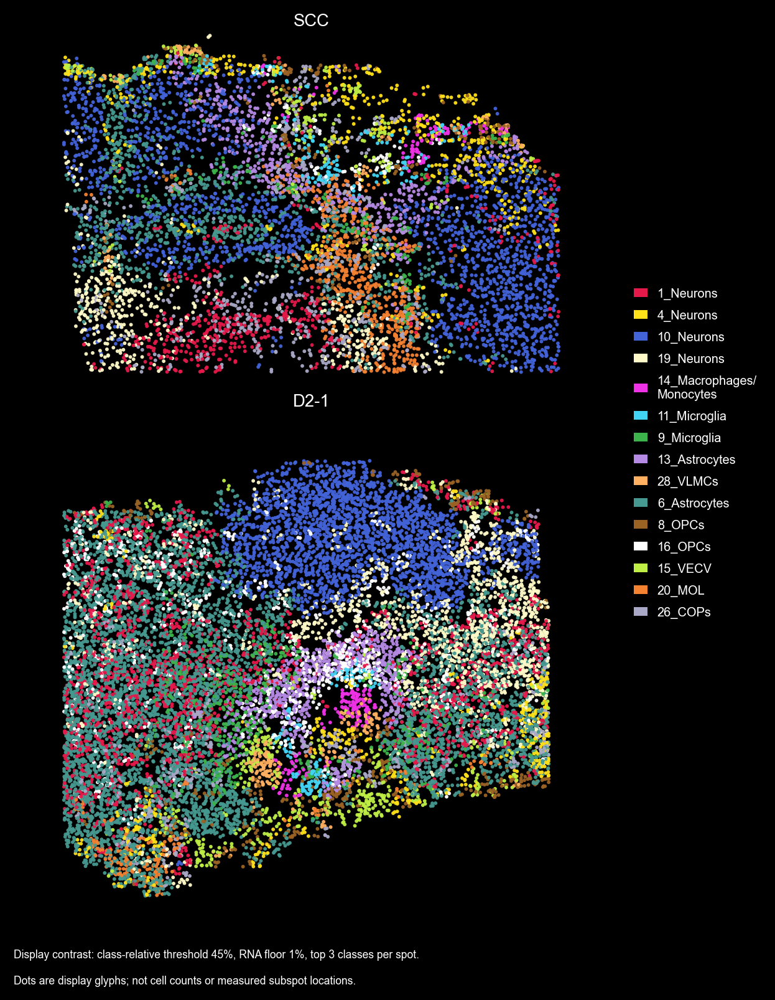

In [4]:
# 中文：根据RNA权重分配显示点，并以固定随机种子绘制两张切片。
# English: Allocate display dots from RNA weights and plot both sections with a fixed random seed.
COLOR = {
    '1_Neurons':'#E6194B', '4_Neurons':'#FFE119',
    '10_Neurons':'#4363D8', '19_Neurons':'#FFFAC8',
    '14_Macrophages_Monocytes':'#F032E6', '11_Microglia':'#42D4F4',
    '9_Microglia':'#3CB44B', '13_Astrocytes':'#B58AE4',
    '28_VLMCs':'#FFB061', '6_Astrocytes':'#469990',
    '8_OPCs':'#9A6324', '16_OPCs':'#FFFFFF',
    '15_VECV':'#BFEF45', '20_MOL':'#F58231', '26_COPs':'#A9A9C7',
}
ALL = list(COLOR)
SELECTED = ALL
FOCUS = ['14_Macrophages_Monocytes','11_Microglia','9_Microglia',
         '13_Astrocytes','28_VLMCs','6_Astrocytes']
MAX_DOTS = 24
DOT_SIZE = 20.0
LOCAL_THRESHOLD = .45
RAW_FLOOR = .01
CONTRAST_POWER = 2.0
MAX_TYPES = 3
ALPHA = .95
SEED = 42
HALF_BOX = .48
def score_for(w, selected):
    raw = w[selected].to_numpy(float)
    assert np.isfinite(raw).all() and np.all(raw >= 0)
    maxima = raw.max(0)
    assert np.all(maxima > 0)
    local = raw / maxima
    local[(local < LOCAL_THRESHOLD) | (raw < RAW_FLOOR)] = 0
    winners = np.argsort(-local, axis=1, kind='stable')[:, :MAX_TYPES]
    keep = np.zeros_like(local, dtype=bool)
    np.put_along_axis(keep, winners, True, axis=1)
    return np.where(keep, local ** CONTRAST_POWER, 0)

def dots_for(w, xy, selected, score, cap, denominator):
    total = score.sum(1)
    budgets = np.where(total > 0,
        np.clip(np.rint(total / denominator * cap), 1, cap), 0).astype(int)
    allocation = np.zeros_like(score, dtype=int)
    pitch = float(cKDTree(xy).query(xy, k=2)[0][:, 1].min())
    assert pitch > 0
    pieces = []
    for i, center in enumerate(xy):
        n = int(budgets[i])
        if n == 0:
            continue
        ideal = score[i] / total[i] * n
        count = np.floor(ideal).astype(int)
        remainder = n - int(count.sum())
        if remainder:
            count[np.argsort(-(ideal-count), kind='stable')[:remainder]] += 1
        allocation[i] = count
        assert count.sum() == n and np.all(count[score[i] == 0] == 0)
        # Seed per spot keeps its jitter reproducible across all candidates.
        rng = np.random.default_rng(np.random.SeedSequence([SEED, i]))
        offset = rng.uniform(-HALF_BOX*pitch, HALF_BOX*pitch, (24, 2))[:n]
        identity = rng.permutation(np.repeat(np.arange(len(selected)), count))
        assert np.max(np.abs(offset)) <= HALF_BOX*pitch
        piece = pd.DataFrame({
            'spot_id':str(w.index[i]), 'x_display':center[0]+offset[:,0],
            'y_display':center[1]+offset[:,1],
            'cell_type':np.asarray(selected)[identity],
        })
        pieces.append(piece)
    points = pd.concat(pieces, ignore_index=True)
    order = np.random.default_rng(SEED).permutation(len(points))
    points = points.iloc[order].reset_index(drop=True)
    alloc = pd.DataFrame(allocation, index=w.index, columns=selected)
    assert np.all((allocation > 0).sum(1) <= MAX_TYPES)
    assert np.all(allocation.sum(1) == budgets)
    assert points.cell_type.nunique() == len(selected)
    return points, alloc

style(9)
fig,axs=plt.subplots(2,1,figsize=(8,9.2),gridspec_kw={'height_ratios':[35,50]})
fig.subplots_adjust(left=.025,right=.70,bottom=.09,top=.94,hspace=.08)
fig.patch.set_facecolor('black')
for ax,(name,weights,meta,ylim) in zip(axs,[('SCC',W,w,(0,35)),('D2-1',DW,d,(50.5,.5))]):
    score=score_for(weights,SELECTED)
    points,allocation=dots_for(weights,meta[['x','y']].to_numpy(),SELECTED,score,MAX_DOTS,float(score.sum(1).max()))
    ax.set_facecolor('black')
    ax.scatter(points.x_display,points.y_display,c=points.cell_type.map(COLOR),s=5.5,alpha=ALPHA,linewidths=0)
    ax.set(xlim=(0,51),ylim=ylim,aspect='equal');ax.axis('off')
    ax.set_title(name,color='white',fontsize=11,pad=3)
handles=[Patch(facecolor=COLOR[c],label=type_title(c)) for c in SELECTED]
fig.legend(handles=handles,loc='center left',bbox_to_anchor=(.71,.53),fontsize=8,
           labelcolor='white',labelspacing=.8,handlelength=1.1)
fig.text(.03,.04,'Display contrast: class-relative threshold 45%, RNA floor 1%, top 3 classes per spot.',color='white',fontsize=7)
fig.text(.03,.015,'Dots are display glyphs; not cell counts or measured subspot locations.',color='white',fontsize=7)
render(fig,'Figure6a_RCTD_dot_density',axes=list(axs))


## Figure 6b–f and Extended Data 4c — Reference regions and C1 distance / 参考区域与C1距离

English: H&E overlays use registered spot positions. The reference UMAP, projected D2 embedding and transferred region labels define the C1 region. Distances are measured to the nearest C1 spot center in units of grid spacing. The H&E panel also supplies Extended Data 4c.

中文：H&E叠加图使用配准后的spot位置，参考UMAP、D2投射和转移标签确定C1区域。距离取至最近C1 spot中心的网格间距，H&E同时对应扩展图4c。


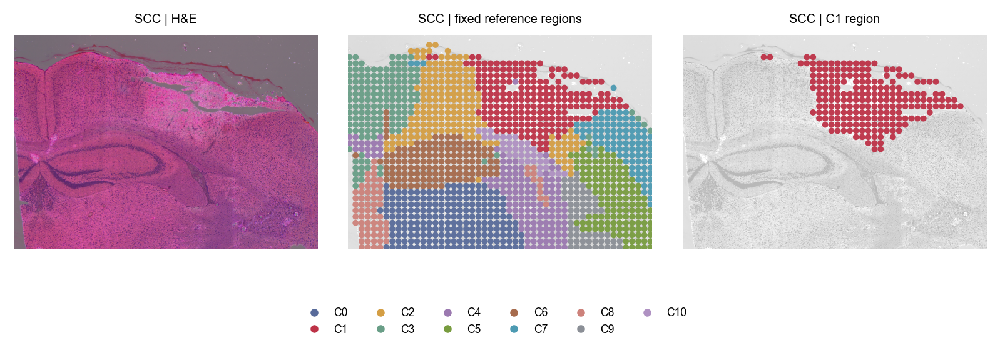

In [5]:
# 中文：显示H&E及配准后的参考区域和C1叠加图。
# English: Display H&E with registered reference-region and C1 overlays.
style(7)
fig,axs=plt.subplots(1,3,figsize=(9,3.8))
fig.subplots_adjust(left=.025,right=.985,bottom=.24,top=.86,wspace=.10)
for ax,title_,mode in zip(axs,['SCC | H&E','SCC | fixed reference regions','SCC | C1 region'],['none','all','C1']):
    ax.imshow(he if mode=='none' else gray,cmap=None if mode=='none' else 'gray',vmin=0,vmax=1,origin='upper',interpolation='nearest')
    ax.set(xlim=(0,950),ylim=(950,280));ax.axis('off');ax.set_title(title_,pad=8)
    if mode!='none':
        mask=w.WSC_region.eq('WSC_C1').to_numpy() if mode=='C1' else np.ones(len(w),bool)
        ax.scatter(w.HE_pixel_x[mask],w.HE_pixel_y[mask],c=w.WSC_region[mask].map(cp),s=1,linewidths=0,alpha=.95)
        fig.canvas.draw();diam=np.linalg.norm(ax.transData.transform((950/99*2,0))-ax.transData.transform((0,0)))*72/fig.dpi
        ax.collections[-1].set_sizes([diam**2])
handles=[Line2D([],[],marker='o',ls='none',color=cp[r],markersize=4,label=r.replace('WSC_','')) for r in regions]
fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.075),ncol=6,fontsize=7)
render(fig,'Figure6b_Extended4c_reference_HE',axes=list(axs))


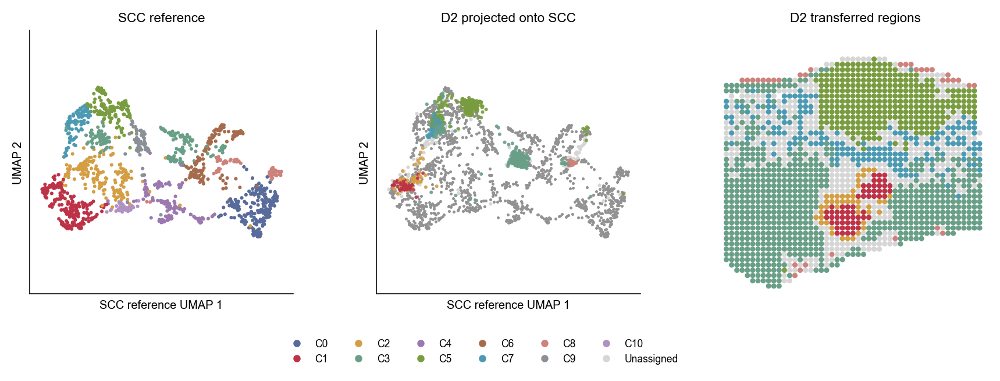

In [6]:
# 中文：显示固定参考UMAP、D2投射和原坐标上的区域标签。
# English: Show fixed reference UMAP, D2 projection and transferred labels in native coordinates.
style(8)
allxy=np.vstack([rxy,qxy]);mid=(allxy.min(0)+allxy.max(0))/2;half=np.max(np.ptp(allxy,axis=0))*.55
fig,axs=plt.subplots(1,3,figsize=(10,4))
fig.subplots_adjust(left=.065,right=.985,bottom=.23,top=.86,wspace=.29)
axs[0].scatter(*rxy.T,c=w.WSC_region.map(cp),s=6,linewidths=0)
axs[1].scatter(*rxy.T,c='#929292',s=4,linewidths=0)
assigned=d.WSC_region.ne('Unassigned').to_numpy()
axs[1].scatter(*qxy[~assigned].T,c=cp['Unassigned'],s=6,linewidths=0)
axs[1].scatter(*qxy[assigned].T,c=d.loc[assigned,'WSC_region'].map(cp),s=6,linewidths=0,alpha=.9)
for ax,title_ in zip(axs[:2],['SCC reference','D2 projected onto SCC']):
    ax.set(xlim=(mid[0]-half,mid[0]+half),ylim=(mid[1]-half,mid[1]+half),aspect='equal',xticks=[],yticks=[],xlabel='SCC reference UMAP 1',ylabel='UMAP 2',title=title_)
axs[2].scatter(d.x,d.y,c=d.WSC_region.map(cp),s=1,linewidths=0)
axs[2].set(xlim=(.5,50.5),ylim=(50.5,.5),aspect='equal',title='D2 transferred regions');axs[2].axis('off')
fig.canvas.draw();diam=axs[2].get_window_extent().width/fig.dpi*72/50;axs[2].collections[0].set_sizes([diam**2])
handles=[Line2D([],[],marker='o',ls='none',color=cp[r],markersize=4,label=r.replace('WSC_','')) for r in regions+['Unassigned']]
fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.04),ncol=6,fontsize=7)
render(fig,'Figure6cde_reference_transfer',axes=list(axs))


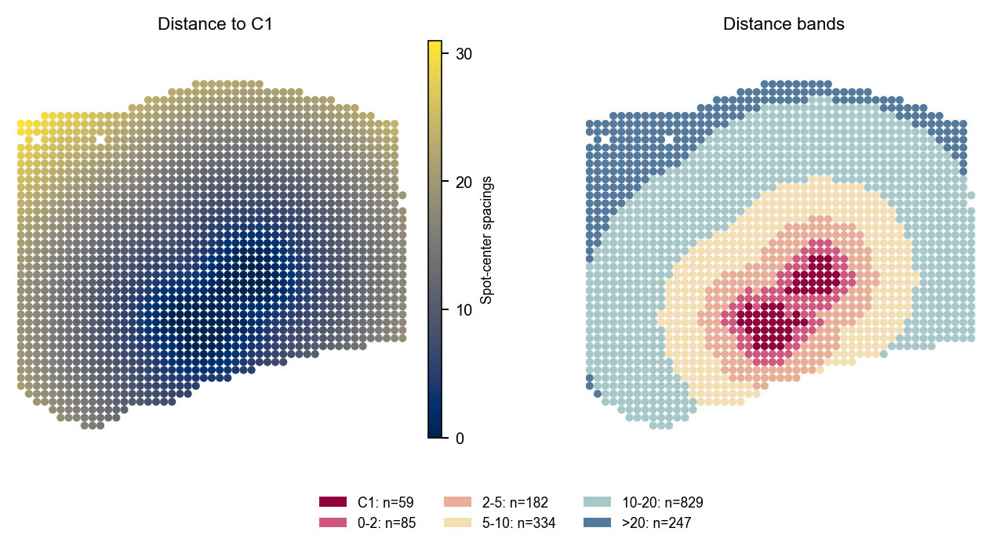

In [7]:
# 中文：计算至最近C1 spot中心的距离，显示连续值与六个区间。
# English: Calculate distances to the nearest C1 spot center and show continuous values and six bands.
style(8)
fig,axs=plt.subplots(1,2,figsize=(8,4.4));fig.subplots_adjust(left=.04,right=.94,bottom=.22,top=.86,wspace=.27)
colors_distance=['#8f003d','#cf597e','#e8ae97','#f2dfb4','#a7c7c8','#547a9b']
for ax,val,cmap,vmin,vmax,title_ in [
    (axs[0],distance,'cividis',0,31,'Distance to C1'),
    (axs[1],pd.Categorical(calculated_band,categories=bands,ordered=True).codes,ListedColormap(colors_distance),-.5,5.5,'Distance bands')]:
    coll=EllipseCollection(np.ones(len(d)),np.ones(len(d)),np.zeros(len(d)),units='xy',offsets=d[['x','y']].to_numpy(),offset_transform=ax.transData,cmap=cmap,norm=Normalize(vmin,vmax),edgecolors='none')
    coll.set_array(np.asarray(val));ax.add_collection(coll)
    ax.set(xlim=(.5,50.5),ylim=(50.5,.5),aspect='equal',title=title_);ax.axis('off')
fig.canvas.draw();box=axs[0].get_position();cax=fig.add_axes([box.x1+.012,box.y0,.012,box.height])
fig.colorbar(mpl.cm.ScalarMappable(norm=Normalize(0,31),cmap='cividis'),cax=cax,ticks=[0,10,20,30]).set_label('Spot-center spacings',fontsize=7)
fig.legend(handles=[Patch(facecolor=c,label=f'{b}: n={int(band_counts[b])}') for b,c in zip(bands,colors_distance)],loc='lower center',bbox_to_anchor=(.5,.05),ncol=3,fontsize=7)
render(fig,'Figure6f_C1_distance',axes=list(axs))


## Figure 6g–h — C-SIDE / C-SIDE分析

English: The volcano displays five cell classes from the fitted continuous-proximity model. Heatmap colors show fitted expression; black dots indicate significant gene–class tests in that model. Gray cells denote unavailable predictions.

中文：火山图展示连续邻近度模型中的五类细胞。热图颜色为拟合表达，黑点表示模型中显著的基因–细胞类别检验，灰色表示无有效预测值。


In [8]:
# 中文：载入完整C-SIDE结果并计算类别内BH校正。
# English: Load complete C-SIDE results and calculate within-class BH correction.
cs_all=read('CSIDE_results.csv.gz')
for cell_type_,q in cs_all.groupby('cell_type',sort=False):
    assert np.allclose(multipletests(q.p_val,method='fdr_bh')[1],q.q_value,atol=5e-13,rtol=1e-10)
cs_results=cs_all.loc[~cs_all.excluded_gene_family].copy()
assert not cs_results.duplicated(['gene_id','cell_type']).any()
assert np.allclose(cs_results.log2FC_proximal_vs_distant,cs_results.log_fc/np.log(2))
assert np.array_equal(cs_results.significant,cs_results.q_value.lt(.01)&cs_results.log_fc.abs().ge(.4))
print('C-SIDE stored tests:',len(cs_results),'; displayed five-class tests:',int(cs_results.cell_type.isin(expression_focus).sum()))


C-SIDE stored tests: 11799 ; displayed five-class tests: 3090


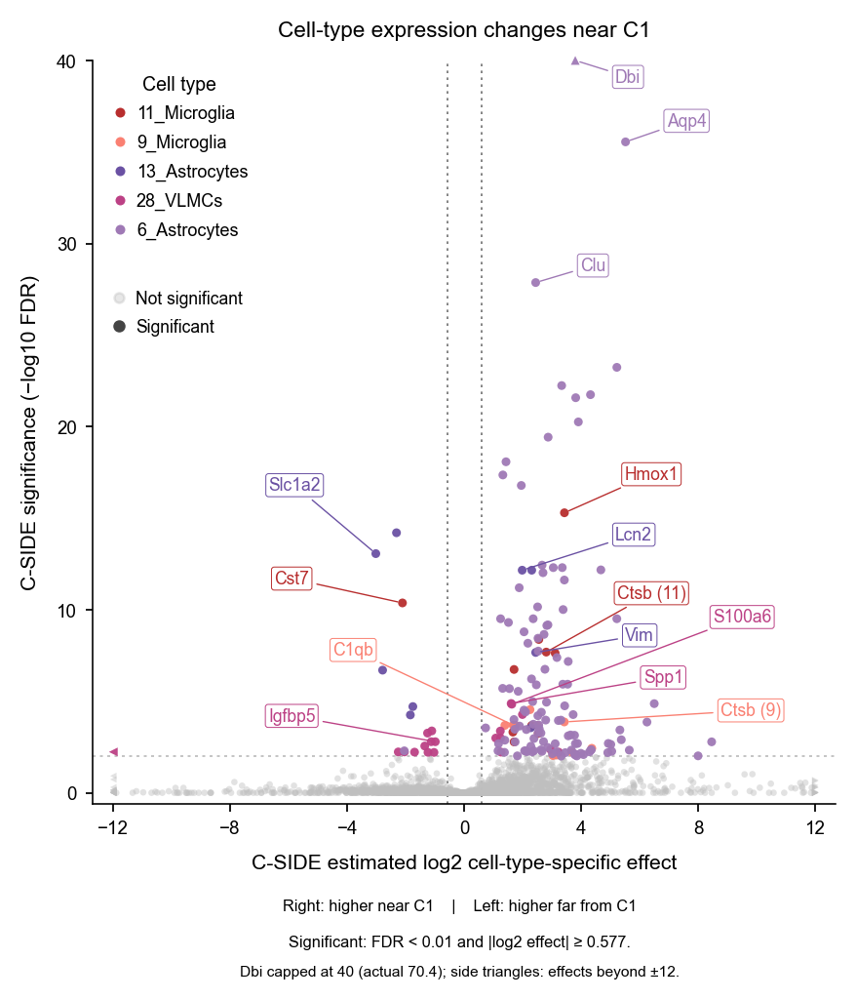

In [9]:
# 中文：绘制五类细胞的火山图和基因标签。
# English: Plot the five-class volcano with gene annotations.
style(7)
NAME = '05_supported_focus_CSIDE_volcano_combined'

data = cs_results.copy()
volcano_types = expression_focus
data = data[data.cell_type.isin(volcano_types)].copy()
assert data[['gene_id', 'cell_type']].duplicated().sum() == 0
assert np.isfinite(data.log2FC_proximal_vs_distant).all()
assert data.q_value.between(0, 1, inclusive='right').all()
# q values are strictly positive before applying the negative logarithm.
data['minus_log10_FDR'] = -np.log10(data.q_value)
data['display_x'] = data.log2FC_proximal_vs_distant.clip(-12, 12)
data['display_y'] = data.minus_log10_FDR.clip(upper=40)
data['edge_marker'] = np.select(
    [data.log2FC_proximal_vs_distant.lt(-12), data.log2FC_proximal_vs_distant.gt(12)],
    ['<', '>'], default='o')
data.loc[data.minus_log10_FDR.gt(40), 'edge_marker'] = '^'
data['color_hex'] = data.cell_type.map(col)

# Label selected significant gene-class pairs; candidates without significant
# differential expression are omitted from the annotation layer.
shown = {
    '11_Microglia': ['Cst7', 'Hmox1', 'Ctsb'],
    '9_Microglia': ['C1qb', 'Ctsb', 'Fcrls'],
    '13_Astrocytes': ['Lcn2', 'Slc1a2', 'Vim'],
    '28_VLMCs': ['Igfbp5', 'Spp1', 'S100a6'],
    '6_Astrocytes': ['Dbi', 'Aqp4', 'Clu'],
}
annotations = pd.concat([
    data[data.cell_type.eq(c) & data.significant & data.gene_symbol.isin(shown[c])]
    for c in volcano_types
], ignore_index=True)
assert len(annotations) == 14

# All observations use the same linear axes. ±12 is the original horizontal
# plotting window; explicit edge triangles retain out-of-window observations.
fig, ax = plt.subplots(figsize=(5.1, 5.8))
fig.subplots_adjust(left=.14, right=.97, bottom=.18, top=.94)
ax.axvline(-.4 / np.log(2), color='#777777', lw=.7, ls=(0, (1.5, 2.5)), zorder=0)
ax.axvline(.4 / np.log(2), color='#777777', lw=.7, ls=(0, (1.5, 2.5)), zorder=0)
ax.axhline(2, color='#b3b3b3', lw=.6, ls=(0, (2, 3)), zorder=0)
for significant in [False, True]:
    for c in volcano_types:
        z = data[data.cell_type.eq(c) & data.significant.eq(significant)]
        for marker in ['o', '<', '>', '^']:
            zz = z[z.edge_marker.eq(marker)]
            if zz.empty:
                continue
            ax.scatter(zz.display_x, zz.display_y,
                       s=13 if significant else 7, color=col(c) if significant else '#bfbfbf',
                       alpha=.95 if significant else .45, marker=marker,
                       edgecolors='none', linewidths=0,
                       zorder=3 if significant else 1, rasterized=False,
                       clip_on=marker != '^')
ax.set_xlim(-12.7, 12.7)
ax.set_ylim(-.6, 40)
# Square physical plotting rectangle; x/y units retain their own data scales.
ax.set_box_aspect(1)
ax.set_xticks([-12, -8, -4, 0, 4, 8, 12])
ax.set_yticks([0, 10, 20, 30, 40])
ax.set_xlabel('C-SIDE estimated log2 cell-type-specific effect', fontsize=8.5, labelpad=7)
ax.set_ylabel('C-SIDE significance (−log10 FDR)', fontsize=8.5, labelpad=7)
ax.tick_params(labelsize=7.5, width=.7, length=3)
ax.set_title('Cell-type expression changes near C1', fontsize=9, pad=10)

handles = [Line2D([], [], marker='o', linestyle='none', markersize=4,
                  markerfacecolor=col(c), markeredgewidth=0, label=type_title(c)) for c in volcano_types]
legend = ax.legend(handles=handles, title='Cell type', loc='upper left',
                   bbox_to_anchor=(.015, .99), borderaxespad=0,
                   fontsize=7.2, title_fontsize=7.8, handlelength=1,
                   handletextpad=.45, labelspacing=.65)
ax.add_artist(legend)
ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='none', color='#bbbbbb', alpha=.35,
           markersize=4, label='Not significant'),
    Line2D([], [], marker='o', linestyle='none', color='#444444',
           markersize=4, label='Significant'),
], loc='upper left', bbox_to_anchor=(.015, .70), borderaxespad=0,
          fontsize=7, handlelength=1, handletextpad=.45, labelspacing=.6)

# Positions are figure annotations only. Every leader terminates at its actual
# gene/type result; duplicated Ctsb labels include the original type identifier.
positions = {
    ('6_Astrocytes', 'Dbi'): (5.6, 39.1),
    ('6_Astrocytes', 'Aqp4'): (7.6, 36.7),
    ('6_Astrocytes', 'Clu'): (4.4, 28.8),
    ('13_Astrocytes', 'Slc1a2'): (-5.8, 16.8),
    ('11_Microglia', 'Cst7'): (-5.9, 11.7),
    ('28_VLMCs', 'Igfbp5'): (-5.9, 4.2),
    ('9_Microglia', 'C1qb'): (-3.8, 7.8),
    ('11_Microglia', 'Hmox1'): (6.4, 17.4),
    ('13_Astrocytes', 'Lcn2'): (5.8, 14.1),
    ('11_Microglia', 'Ctsb'): (6.4, 10.9),
    ('13_Astrocytes', 'Vim'): (6.0, 8.6),
    ('28_VLMCs', 'Spp1'): (6.8, 6.3),
    ('28_VLMCs', 'S100a6'): (9.5, 9.6),
    ('9_Microglia', 'Ctsb'): (9.8, 4.5),
}
label_rows = []
for r in annotations.itertuples():
    key = (r.cell_type, r.gene_symbol)
    label = r.gene_symbol + (' (' + r.cell_type.split('_')[0] + ')' if r.gene_symbol == 'Ctsb' else '')
    xytext = positions[key]
    ax.annotate(label, xy=(r.display_x, r.display_y), xytext=xytext,
                ha='center', va='center', color=col(r.cell_type), fontsize=7,
                bbox=dict(boxstyle='round,pad=.16', fc='white', ec=col(r.cell_type), lw=.4, alpha=.98),
                arrowprops=dict(arrowstyle='-', color=col(r.cell_type), lw=.55,
                                shrinkA=2, shrinkB=2), zorder=5)
    label_rows.append(dict(cell_type=r.cell_type, gene_id=r.gene_id,
                           gene_symbol=r.gene_symbol, label=label,
                           actual_x=r.log2FC_proximal_vs_distant,
                           actual_y=r.minus_log10_FDR,
                           plotted_y=r.display_y,
                           label_x=xytext[0], label_y=xytext[1], color_hex=col(r.cell_type)))

fig.text(.55, .09, 'Right: higher near C1    |    Left: higher far from C1',
         ha='center', fontsize=6.5)
fig.text(.55, .055, 'Significant: FDR < 0.01 and |log2 effect| ≥ 0.577.',
         ha='center', fontsize=6.5)
fig.text(.55, .026, 'Dbi capped at 40 (actual 70.4); side triangles: effects beyond ±12.',
         ha='center', fontsize=6.2)
fig.canvas.draw()
plot_box = ax.get_window_extent(fig.canvas.get_renderer())
plot_width_pt = plot_box.width / fig.dpi * 72
plot_height_pt = plot_box.height / fig.dpi * 72
assert abs(plot_width_pt - plot_height_pt) < .01

render(fig,'Figure6g_CSIDE_volcano',axes=[ax])


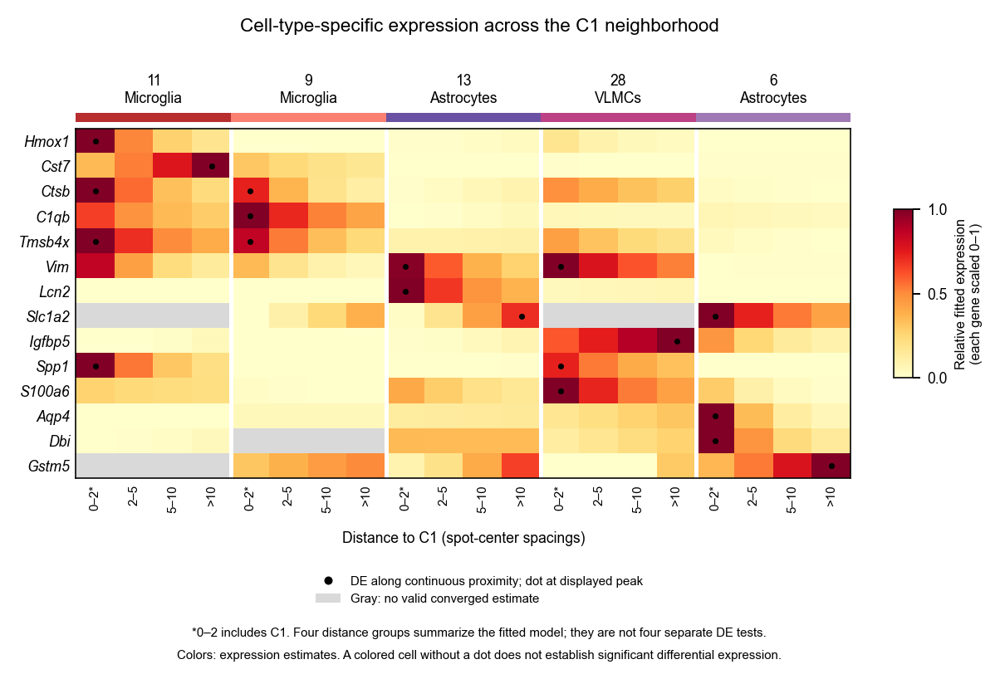

In [10]:
# 中文：重建14基因×五类×四距离组热图，并区分拟合值与显著性。
# English: Rebuild the 14-gene, five-class, four-distance heatmap and separate expression from significance.
style(7)
from matplotlib.lines import Line2D
pred=read('CSIDE_predictions.csv.gz')
sel=read('CSIDE_selected_genes.csv').drop_duplicates('gene_id')
symbols=sel.gene_symbol.tolist()
bins=['0-2_including_C1','2-5','5-10','>10']
columns=[f'{c}|{b}' for c in expression_focus for b in bins]
pred['column']=pred.cell_type+'|'+pred.distance_band
# Show converged finite estimates, including valid fits not admitted to a DE test.
# Such cells receive no significance marker. Do not turn a failed estimate into color.
pred['displayed']=pred.converged & ~pred.error_flag & np.isfinite(pred.fitted_mean_CP10000) & pred.fitted_mean_CP10000.ge(0)
values=pred.pivot(index='gene_symbol',columns='column',values='fitted_mean_CP10000').reindex(index=symbols,columns=columns)
mask=pred.pivot(index='gene_symbol',columns='column',values='displayed').reindex(index=symbols,columns=columns)
values=values.where(mask)
lo=values.min(axis=1);span=values.max(axis=1)-lo
scaled=values.sub(lo,axis=0).div(span.replace(0,np.nan),axis=0)
fig,ax=plt.subplots(figsize=(7.1,max(4.5,.18*len(symbols)+1.9)))
fig.subplots_adjust(left=.12,right=.85,bottom=.29,top=.81)
cmap=plt.get_cmap('YlOrRd').copy();cmap.set_bad('#d9d9d9')
im=ax.imshow(np.ma.masked_invalid(scaled.to_numpy()),vmin=0,vmax=1,cmap=cmap,interpolation='nearest',aspect='auto')
ax.set_yticks(np.arange(len(symbols)),symbols,fontsize=7,fontstyle='italic')
ax.set_xticks(np.arange(len(columns)),['0–2*','2–5','5–10','>10']*len(expression_focus),rotation=90,ha='right',va='center',rotation_mode='anchor',fontsize=6)
ax.tick_params(axis='both',length=0,pad=3)
for j,c in enumerate(expression_focus):
 start=j*4-.5
 ax.add_patch(Rectangle((start,1.02),4,.025,transform=ax.get_xaxis_transform(),clip_on=False,facecolor=col(c),edgecolor='none'))
 ax.text(start+2,1.065,type_title(c).replace('_','\n',1),transform=ax.get_xaxis_transform(),ha='center',va='bottom',fontsize=7)
 if j:ax.axvline(start,color='white',lw=2)
 # One dot per significant gene/type; the continuous DE test is not a test per bin.
 for i,g in enumerate(symbols):
  zz=pred[pred.gene_symbol.eq(g)&pred.cell_type.eq(c)]
  if zz.DE_significant.any():
   v=scaled.loc[g,columns[j*4:j*4+4]]
   if v.notna().any():
    k=int(np.nanargmax(v.to_numpy()));ax.scatter(j*4+k,i,s=8,c='black',marker='o',linewidths=0)
for spine in ax.spines.values():spine.set_visible(True)
cax=fig.add_axes([.89,.44,.018,.25]);cb=fig.colorbar(im,cax=cax);cb.set_ticks([0,.5,1]);cb.set_label('Relative fitted expression\n(each gene scaled 0–1)',fontsize=6.5)
ax.set_xlabel('Distance to C1 (spot-center spacings)',labelpad=9)
fig.suptitle('Cell-type-specific expression across the C1 neighborhood',fontsize=9,y=.975)
fig.legend(handles=[Line2D([],[],marker='o',color='black',linestyle='none',markersize=3,label='DE along continuous proximity; dot at displayed peak'),
 Patch(facecolor='#d9d9d9',label='Gray: no valid converged estimate')],loc='lower center',bbox_to_anchor=(.5,.085),fontsize=6,ncol=1)
fig.text(.5,.055,'*0–2 includes C1. Four distance groups summarize the fitted model; they are not four separate DE tests.',ha='center',fontsize=6)
fig.text(.5,.022,'Colors: expression estimates. A colored cell without a dot does not establish significant differential expression.',ha='center',fontsize=6)

render(fig,'Figure6h_CSIDE_expression_heatmap',axes=[ax])


## Figure 6i–l and Extended Data 3a — Expression and spatial autocorrelation / 表达与空间自相关

English: Gene-level expression and four-neighbor Moran's I are calculated for each capture. The D3–D0 comparison includes 18,161 genes. Four ten-capture maps show Hmox1, Lyz2, Spp1 and Vim. Figure 6k summarizes mean log-normalized expression across all spots, including zeros, within each capture.

中文：逐样本计算基因表达和四邻接Moran自相关，D3与D0比较包含18,161个基因。四张十样本图展示Hmox1、Lyz2、Spp1和Vim；6k使用每次采样全部spot（含零值）的平均log归一化表达。


In [11]:
# 中文：构建逐样本四邻接图，重算基因筛选、表达变化和Moran统计。
# English: Build within-capture four-neighbor graphs and recompute gene filtering, expression changes and Moran statistics.
def make_W(xy):
    e=cKDTree(xy).query_pairs(1.000000001,output_type='ndarray')
    A=sparse.csr_matrix((np.ones(2*len(e)),(np.r_[e[:,0],e[:,1]],np.r_[e[:,1],e[:,0]])),shape=(len(xy),len(xy)))
    degree=np.asarray(A.sum(axis=1)).ravel()
    return A,sparse.diags(1/np.maximum(degree,1))@A,degree
def moran_values(values,W):
    z=np.asarray(values,dtype=np.float64);z=z-z.mean(axis=0)
    den=np.sum(z*z,axis=0)
    return np.where(den>1e-12,len(z)/W.sum()*np.sum(z*(W@z),axis=0)/np.maximum(den,1e-20),np.nan)
sample_linear=np.stack([np.asarray(linear[idx].mean(axis=0)).ravel() for idx in sample_indices])
sample_log=np.stack([np.asarray(logmatrix[idx].mean(axis=0)).ravel() for idx in sample_indices])
sample_detected=np.stack([np.asarray((raw[idx]>0).sum(axis=0)).ravel() for idx in sample_indices])
detected_samples=(sample_detected>0).sum(axis=0);detection=sample_detected.sum(axis=0)/len(spots)
mean_linear_D0=sample_linear[:2].mean(axis=0);mean_linear_D3=sample_linear[7:].mean(axis=0)
prefilter=(detected_samples>=2)&(detection>=.01)&((mean_linear_D0>0)|(mean_linear_D3>0))
candidates=np.flatnonzero(prefilter);moran_matrix=np.full((10,len(genes)),np.nan);graphs=[]
for si,idx in enumerate(sample_indices):
    A,Wg,degree=make_W(spots.loc[idx,['x','y']].to_numpy())
    assert (degree>0).all() and degree.max()<=4;graphs.append(Wg)
    for first in range(0,len(candidates),512):
        j=candidates[first:first+512]
        moran_matrix[si,j]=moran_values(logmatrix[idx][:,j].toarray(),Wg)
valid=np.isfinite(moran_matrix)
retained=prefilter&(valid.sum(axis=0)>=4)&valid[:2].all(axis=0)&valid[7:].all(axis=0)
filter_reference=read('gene_filter_reference.csv.gz').set_index('gene').loc[genes]
assert np.array_equal(retained,filter_reference.passed_filter)
table=read('gene_statistics_reference.csv.gz');positions=genes.get_indexer(table.gene)
assert len(table)==18161 and set(table.gene)==set(genes[retained])
fc=np.log2((mean_linear_D3[positions]+.001)/(mean_linear_D0[positions]+.001))
delta=moran_matrix[7:,positions].mean(axis=0)-moran_matrix[:2,positions].mean(axis=0)
gene_numeric_error=max(float(np.max(np.abs(fc-table.log2FC_D3_vs_D0))),float(np.nanmax(np.abs(moran_matrix[:,positions].T-table[['Moran_'+s for s in SAMPLES]].to_numpy()))))
assert gene_numeric_error<1e-10,gene_numeric_error
q90=float(np.quantile(delta,.90,method='linear'))
category=np.select([(fc>=1)&(delta>0)&(delta>=q90),(fc>=1)&(delta>0),(np.abs(fc)<.25)&(delta>0)&(delta>=q90),(np.abs(fc)<.25)&(delta>0)],['A_strong','A_light','B_strong','B_light'],default='Other')
assert np.array_equal(category,table.display_class)
x=table.log2FC_D3_vs_D0.to_numpy();y=table.delta_Moran_D3_minus_D0.to_numpy()
main_labels=CORE+[g for g in ['Gfap','Lcn2','Ctss','Cd68','Cxcl10','Fn1','Lgals1','Serpina3n'] if g in table.loc[table.label_for_plot.notna(),'gene'].tolist()]+['Ddn','Nefm','Timp2']
COLORS={'Other':'#c8cbce','A_light':'#e6c6c4','A_strong':'#ac5265','B_light':'#bfd0df','B_strong':'#477999'}

print(f'{len(table):,} genes; A-strong: {(category=="A_strong").sum():,}; B-strong: {(category=="B_strong").sum():,}')


18,161 genes; A-strong: 938; B-strong: 136


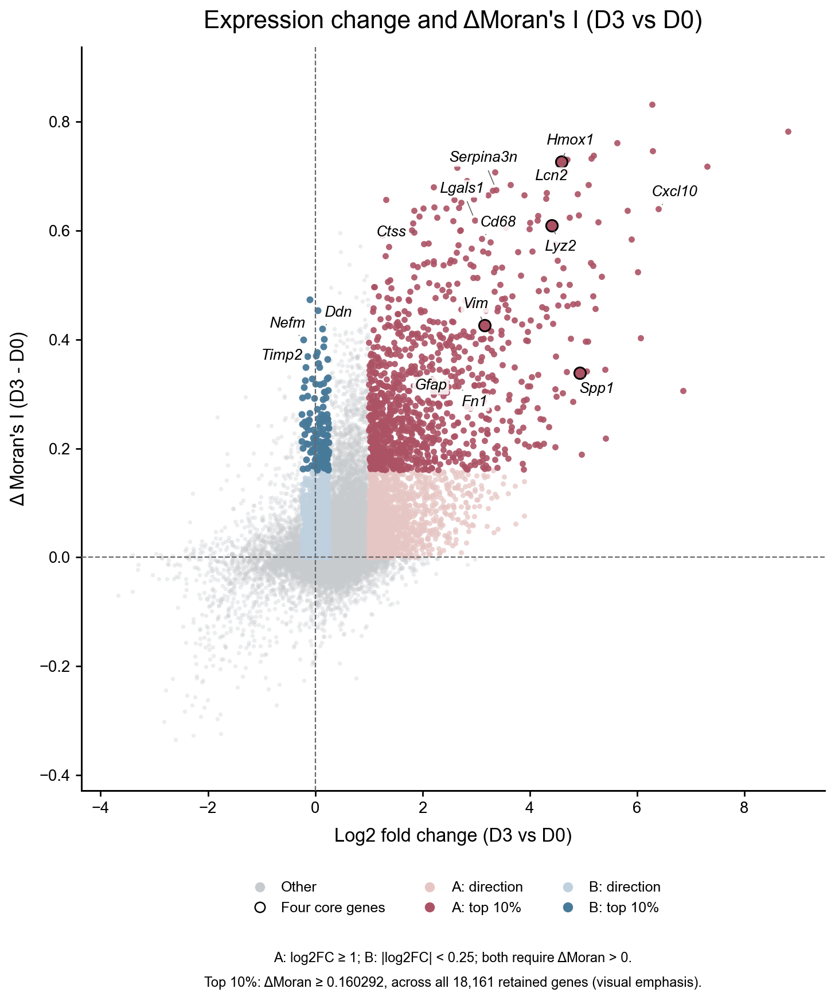

In [12]:
# 中文：绘制基因表达变化与Moran变化的关系。
# English: Plot gene expression change against change in Moran's I.
def apply_style(kind):
    """Apply figure-specific formatting independently of execution order."""
    mpl.rcdefaults()
    settings = {'font.family': FONT, 'font.weight': 'normal', 'axes.titleweight': 'normal',
        'axes.labelweight': 'normal', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.dpi': 600}
    if kind == 'spatial':
        sc.settings.set_figure_params(dpi=120, dpi_save=600, fontsize=10, facecolor='white', frameon=False)
        settings.update({'font.size': 10, 'axes.linewidth': .8})
    elif kind == 'box':
        settings.update({'font.size': 11, 'axes.linewidth': 1.1, 'xtick.labelsize': 11, 'ytick.labelsize': 11})
    elif kind == 'whole_capture':
        settings.update({'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 15, 'xtick.labelsize': 12,
            'ytick.labelsize': 11, 'axes.linewidth': 1.25})
    elif kind == 'scatter':
        settings.update({'font.size': 12, 'axes.labelsize': 13, 'axes.titlesize': 17, 'xtick.labelsize': 11,
            'ytick.labelsize': 11, 'axes.linewidth': 1.2})
    else:
        settings.update({'font.size': 10, 'axes.linewidth': .9, 'axes.unicode_minus': False})
    mpl.rcParams.update(settings)

def collision_free_labels(fig,ax,names,fontsize):
    fig.canvas.draw();renderer=fig.canvas.get_renderer();pixels=fig.dpi/72
    dots=ax.transData.transform(np.c_[x,y]);tree=cKDTree(dots);limits=ax.get_window_extent().padded(-5)
    occupied=[];placed=[];font=FontProperties(family=FONT,style='italic',size=fontsize)
    for name in names:
        r=table.loc[table.gene.eq(name)].iloc[0];xp,yp=ax.transData.transform((r.log2FC_D3_vs_D0,r.delta_Moran_D3_minus_D0))
        width,_,_=renderer.get_text_width_height_descent(name,font,ismath=False);width+=4;height=fontsize*pixels*1.45;candidates=[]
        for radius in [16,24,34,48,66,88,114,145,185]:
            for angle in np.arange(0,360,22.5)*np.pi/180:
                dx=radius*np.cos(angle)*pixels;dy=radius*np.sin(angle)*pixels;cx,cy=xp+dx,yp+dy
                bb=Bbox.from_bounds(cx-width/2,cy-height/2,width,height)
                if not (limits.contains(bb.x0,bb.y0) and limits.contains(bb.x1,bb.y1)):continue
                zero_x,zero_y=ax.transData.transform((0,0))
                if bb.x0-4 <= zero_x <= bb.x1+4 or bb.y0-4 <= zero_y <= bb.y1+4:continue
                if any(bb.padded(3).overlaps(prior.padded(3)) for prior in occupied):continue
                near=tree.query_ball_point([cx,cy],np.hypot(width,height)/2+4);p=dots[near]
                covering=int(np.sum((p[:,0]>=bb.x0-2)&(p[:,0]<=bb.x1+2)&(p[:,1]>=bb.y0-2)&(p[:,1]<=bb.y1+2))) if len(near) else 0
                candidates.append((radius*1.2+min(covering,25)*.8,dx,dy,bb))
        assert candidates,'标签无可用位置：'+name
        _,dx,dy,bb=min(candidates,key=lambda t:t[0]);occupied.append(bb)
        ax.annotate(name,(r.log2FC_D3_vs_D0,r.delta_Moran_D3_minus_D0),xytext=(dx/pixels,dy/pixels),textcoords='offset points',ha='center',va='center',fontproperties=font,color='black',zorder=8,arrowprops=dict(arrowstyle='-',color='#666666',lw=.65,shrinkA=3,shrinkB=4),bbox=dict(boxstyle='round,pad=.13',facecolor='white',edgecolor='none',alpha=.86))
        placed.append(dict(gene=name,dx_points=float(dx/pixels),dy_points=float(dy/pixels)))
    return placed

def scatter_plot(stem,labels):
    fig,ax=plt.subplots(figsize=(9.4,10.0))
    ax.set_box_aspect(1)
    for z,(cls,size,alpha) in enumerate([('Other',9,.33),('A_light',13,.75),('B_light',15,.8),('A_strong',19,.9),('B_strong',23,.95)]):
        m=table.display_class.eq(cls).to_numpy();ax.scatter(x[m],y[m],s=size,c=COLORS[cls],alpha=alpha,linewidths=0,zorder=z+1)
    for r in table.loc[table.gene.isin(CORE)].itertuples():ax.scatter(r.log2FC_D3_vs_D0,r.delta_Moran_D3_minus_D0,s=65,facecolors=COLORS[r.display_class],edgecolors='black',linewidths=1.2,zorder=7)
    ax.axvline(0,color='#676767',ls='--',lw=.9,zorder=6);ax.axhline(0,color='#676767',ls='--',lw=.9,zorder=6)
    xr=max(x.max()-min(0,x.min()),1);yr=max(y.max()-min(0,y.min()),.1)
    ax.set(xlim=(min(0,x.min())-.055*xr,max(0,x.max())+.055*xr),ylim=(min(0,y.min())-.08*yr,max(0,y.max())+.09*yr))
    ax.set_xlabel('Log2 fold change (D3 vs D0)',labelpad=8);ax.set_ylabel("Δ Moran's I (D3 - D0)",labelpad=8)
    ax.set_title("Expression change and ΔMoran's I (D3 vs D0)",pad=13)
    ax.spines[['top','right']].set_visible(False);ax.tick_params(length=4,width=1.1)
    fig.subplots_adjust(left=.13,right=.97,bottom=.20,top=.92)
    # 列顺序：其他/核心，A浅/深，B浅/深，每列清楚展示层级。
    specs=[('Other','Other'),('core','Four core genes'),('A_light','A: direction'),('A_strong','A: top 10%'),('B_light','B: direction'),('B_strong','B: top 10%')]
    handles=[Line2D([0],[0],marker='o',linestyle='',markerfacecolor='white' if c=='core' else COLORS[c],markeredgecolor='black' if c=='core' else 'none',markersize=7,label=l) for c,l in specs]
    legend=fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.55,.067),ncol=3,frameon=False,fontsize=10,columnspacing=2.1,handletextpad=.5)
    fig.text(.55,.034,'A: log2FC ≥ 1; B: |log2FC| < 0.25; both require ΔMoran > 0.',ha='center',fontsize=9.5)
    fig.text(.55,.010,f'Top 10%: ΔMoran ≥ {q90:.6f}, across all {len(table):,} retained genes (visual emphasis).',ha='center',fontsize=9.5)
    placed=collision_free_labels(fig,ax,labels,10.5)
    fig.canvas.draw();ren=fig.canvas.get_renderer()
    assert not ax.xaxis.label.get_window_extent(ren).overlaps(legend.get_window_extent(ren))
    finish(fig,stem.name,pad=.1);return placed

apply_style('scatter')
scatter_plot(Path('Figure6i_expression_change_vs_Moran'),main_labels);


In [13]:
# 中文：定义使用共用分位数色标的十样本空间绘图函数。
# English: Define ten-capture spatial plots with shared quantile-based color limits.
limits=read('spatial_color_limits.csv').set_index('feature')
LIMITS={g:tuple(limits.loc[g,['vmin','vmax']]) if g in limits.index else tuple(np.quantile(gene_expression[g],[.01,.99])) for g in gene_expression}
plotxy=spots[['plot_x','plot_y']].to_numpy();XMAX,YMAX=plotxy.max(axis=0)
def plot_gene_map(gene):
    style(10)
    expr=gene_expression[gene].to_numpy();vmin,vmax=LIMITS[gene]
    fig,axes=plt.subplots(4,3,figsize=(10.3,12.4),layout='constrained');active=[]
    for row,tp in enumerate(TPS):
        samples=[s for s in SAMPLES if SAMPLE_TP[s]==tp]
        for col_,ax in enumerate(axes[row]):
            if col_>=len(samples):ax.set_visible(False);continue
            sample=samples[col_];idx=sample_indices[SAMPLES.index(sample)]
            a=ad.AnnData(sparse.csr_matrix(expr[idx,None]),var=pd.DataFrame(index=[gene]))
            a.obsm['spatial']=plotxy[idx]
            sc.pl.spatial(a,color=gene,basis='spatial',use_raw=False,cmap='Spectral_r',spot_size=1.,size=1.,scale_factor=1.,img=None,img_key=None,library_id=None,alpha_img=0.,colorbar_loc=None,vmin=vmin,vmax=vmax,sort_order=False,frameon=False,title='',show=False,save=False,ax=ax)
            ax.set(xlim=(-1,XMAX+1),ylim=(YMAX+1,-1),aspect='equal');ax.axis('off')
            ax.set_title(f'{sample}  (n={len(idx):,})',fontsize=11,pad=8);active.append(ax)
    fig.suptitle(gene+' spatial expression',fontsize=15)
    cb=fig.colorbar(mpl.cm.ScalarMappable(norm=Normalize(vmin,vmax),cmap='Spectral_r'),ax=active,fraction=.026,pad=.025,shrink=.72,aspect=28,extend='both')
    cb.set_label('Log-normalized expression',fontsize=10,labelpad=10);cb.ax.tick_params(labelsize=9)
    render(fig,gene+'_all_10_samples',axes=active,pad=.08)


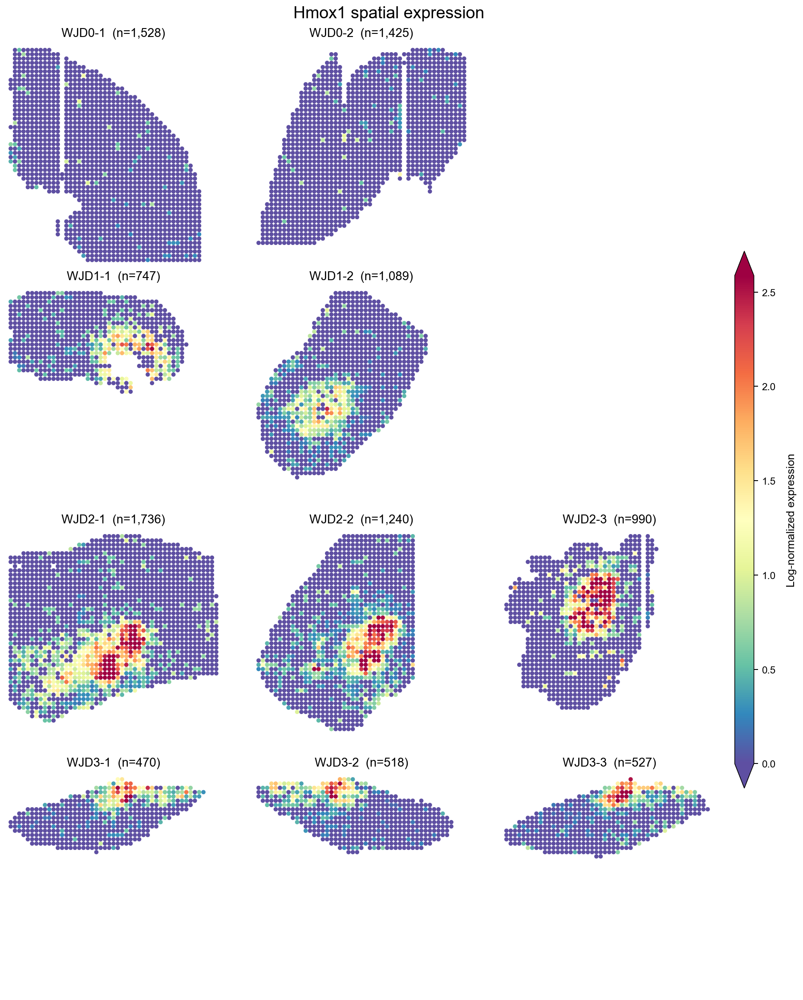

In [14]:
# 中文：图6j及扩展图3a：Hmox1的十样本空间表达。
# English: Figure 6j and Extended Data 3a: Hmox1 expression in all ten captures.
plot_gene_map('Hmox1')


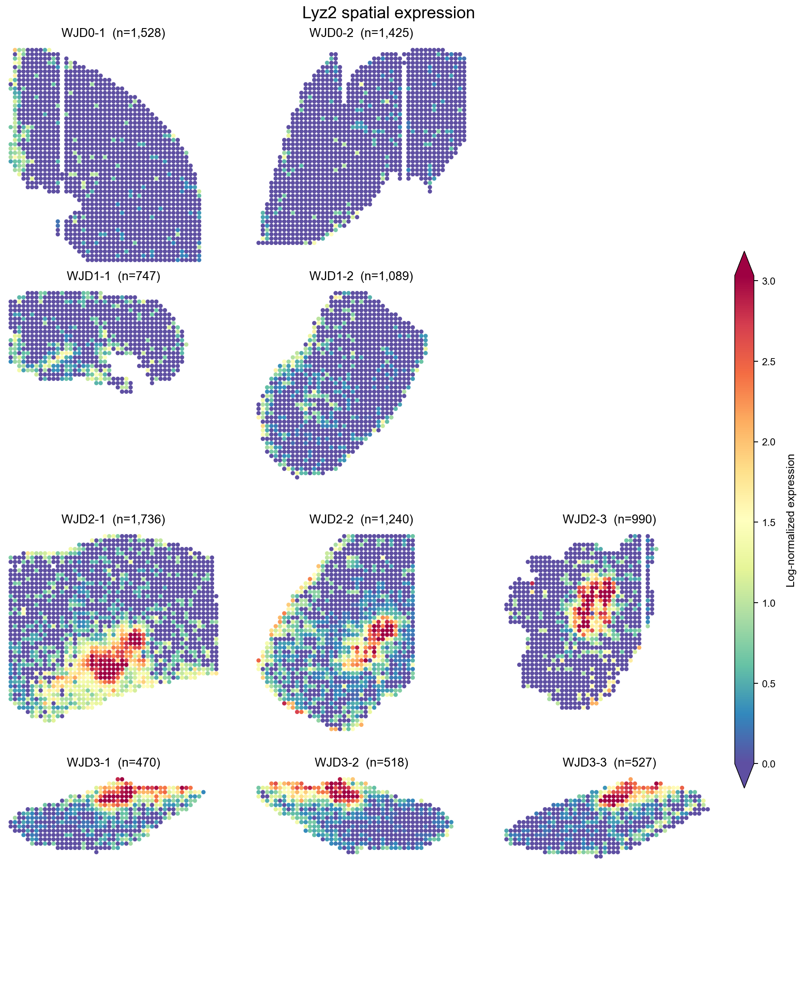

In [15]:
# 中文：图6j及扩展图3a：Lyz2的十样本空间表达。
# English: Figure 6j and Extended Data 3a: Lyz2 expression in all ten captures.
plot_gene_map('Lyz2')


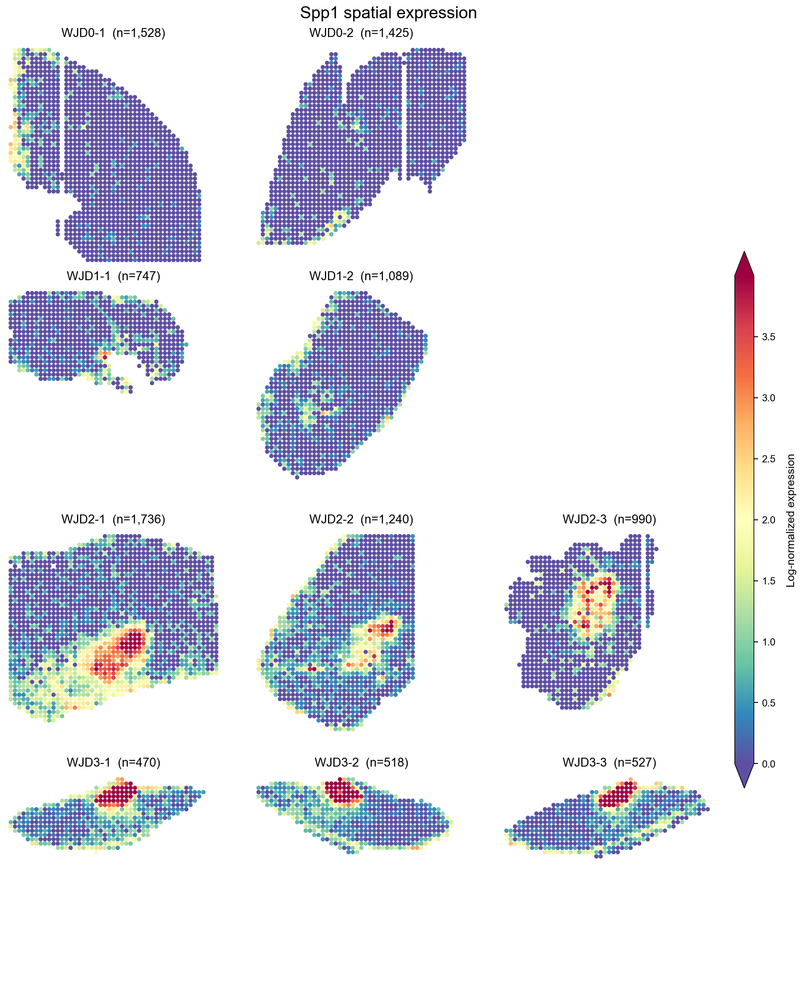

In [16]:
# 中文：图6j及扩展图3a：Spp1的十样本空间表达。
# English: Figure 6j and Extended Data 3a: Spp1 expression in all ten captures.
plot_gene_map('Spp1')


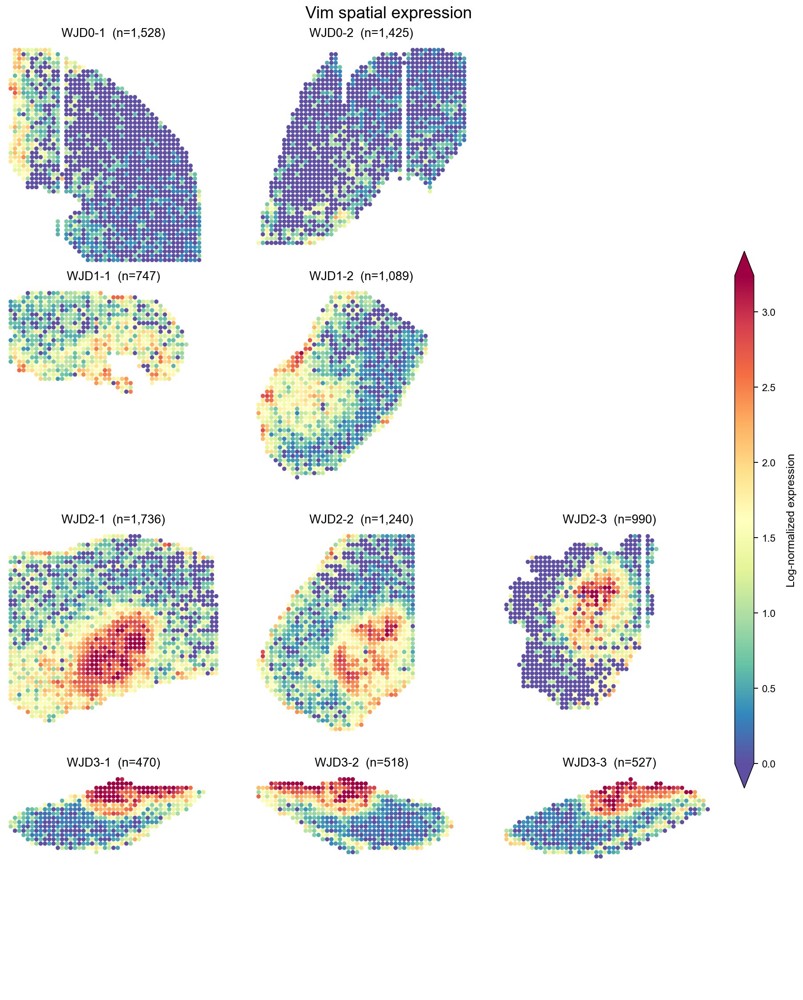

In [17]:
# 中文：图6j及扩展图3a：Vim的十样本空间表达。
# English: Figure 6j and Extended Data 3a: Vim expression in all ten captures.
plot_gene_map('Vim')


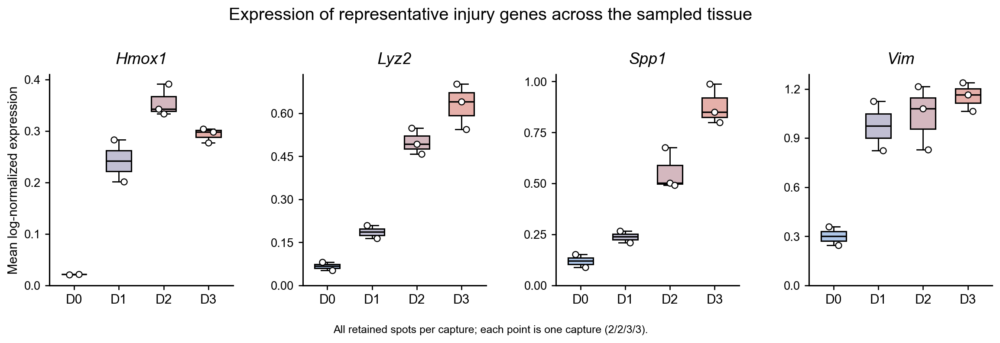

In [18]:
# 中文：图6k：重算全样本表达均值，箱线图叠加全部10个采样点。
# English: Figure 6k: recompute whole-capture means and show all ten capture values.
table4=pd.DataFrame([dict(sample_name=s,timepoint=SAMPLE_TP[s],gene=g,mean_log_normalized_expression=sample_log[si,genes.get_loc(g)]) for si,s in enumerate(SAMPLES) for g in CORE])
expected=read('whole_capture_expression_reference.csv').set_index(['sample_name','gene'])
check=table4.set_index(['sample_name','gene']).loc[expected.index]
assert np.allclose(check.mean_log_normalized_expression,expected.mean_log_normalized_expression,atol=1e-12)
def plot_fig6_4():
    apply_style('whole_capture')
    fig, axes = plt.subplots(1,4,figsize=(13.,4.3))
    for ax,g in zip(axes,CORE):
        vectors = [table4.loc[table4.gene.eq(g)&table4.timepoint.eq(t),'mean_log_normalized_expression'].to_numpy() for t in TPS]
        boxes = ax.boxplot(vectors, positions=range(4), widths=.56, patch_artist=True, showfliers=False, whis=1.5,
            boxprops={'edgecolor':'black','linewidth':1.25},medianprops={'color':'black','linewidth':1.35},
            whiskerprops={'color':'black','linewidth':1.15},capprops={'color':'black','linewidth':1.15})
        for box,t in zip(boxes['boxes'],TPS):box.set_facecolor(PALETTE[t])
        for i,v in enumerate(vectors):ax.scatter(i+np.linspace(-.11,.11,len(v)),v,s=31,facecolor='white',edgecolor='black',linewidth=.95,zorder=4)
        ax.set_title(g,fontstyle='italic',pad=10)
        ax.spines[['top','right']].set_visible(False);ax.tick_params(width=1.1,length=4,pad=4)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5,min_n_ticks=3));ax.set_xticks(range(4),TPS)
        ax.set_xlim(-.55,3.55);ax.set_ylim(bottom=0)
    axes[0].set_ylabel('Mean log-normalized expression')
    fig.suptitle('Expression of representative injury genes across the sampled tissue',fontsize=16,y=.99)
    fig.text(.5,.018,'All retained spots per capture; each point is one capture (2/2/3/3).',ha='center',fontsize=10)
    fig.subplots_adjust(left=.065,right=.995,bottom=.16,top=.79,wspace=.38)
    finish(fig,'Figure6k_whole_capture_expression',pad=.10)
plot_fig6_4()


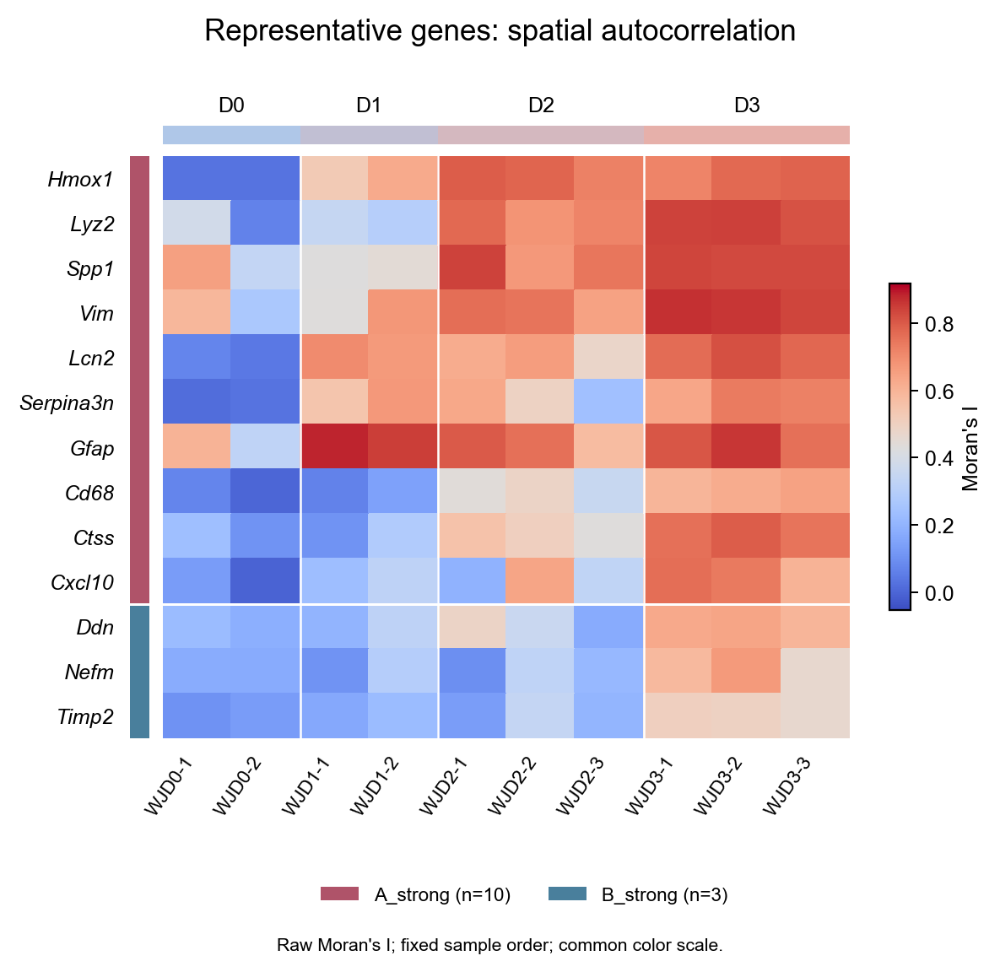

In [19]:
# 中文：按类别内聚类行序绘制Moran热图。
# English: Prepare Moran heatmaps with rows clustered within each category.
matrix=read('gene_heatmap_order.csv.gz')
assert np.allclose(matrix[SAMPLES],moran_matrix[:,genes.get_indexer(matrix.gene)].T,equal_nan=True,atol=1e-10)
rep=read('representative_genes.csv')
representative_matrix=matrix.set_index('gene').loc[rep.gene].reset_index()
CATEGORY_COLORS={'A_strong':'#af5369','B_strong':'#497f9c'}
gene_norm=Normalize(float(matrix[SAMPLES].min().min()),float(matrix[SAMPLES].max().max()))
gene_cmap=plt.get_cmap('coolwarm').copy();gene_cmap.set_bad('#d9d9d9')
def gene_heatmap(df,representative=False):
    n=len(df)
    fig=plt.figure(figsize=(7.8,6.5 if representative else 12.5))
    y0=.24 if representative else .13
    height=.59 if representative else .745
    left=.235 if representative else .17
    width=.58 if representative else .63
    ax=fig.add_axes([left,y0,width,height])
    cat=fig.add_axes([left-.028,y0,.017,height])
    top=fig.add_axes([left,y0+height+.012,width,.018])
    cax=fig.add_axes([left+width+.033,y0+.22*height,.018,.56*height])
    M=df[SAMPLES].to_numpy(float)
    mesh=ax.pcolormesh(np.ma.masked_invalid(M),cmap=gene_cmap,norm=gene_norm,shading='flat',
                       rasterized=False,edgecolors='face',linewidth=.12,antialiased=False)
    ax.set_ylim(n,0);ax.set_xlim(0,10)
    ax.set_xticks(np.arange(10)+.5,SAMPLES,rotation=55,ha='right',fontsize=9)
    ax.tick_params(axis='x',length=0,pad=7)
    if representative:
        ax.set_yticks(np.arange(n)+.5,df.gene.tolist(),fontstyle='italic',fontsize=10)
        ax.tick_params(axis='y',length=0,pad=23)
    else:
        ax.set_yticks([]);ax.set_ylabel(f'{n:,} selected genes',labelpad=44)
    for sp in ax.spines.values():sp.set_visible(False)
    boundary=int(df.category.eq('A_strong').sum())
    # 分块注释用两个矢量矩形，避免1074个同色小格在PDF缩放时出现接缝。
    cat.axhspan(0,boundary,color=CATEGORY_COLORS['A_strong'],lw=0)
    cat.axhspan(boundary,n,color=CATEGORY_COLORS['B_strong'],lw=0)
    cat.set_ylim(n,0);cat.axis('off')
    ax.axhline(boundary,color='white',lw=1.2);cat.axhline(boundary,color='white',lw=1.2)
    for b in [2,4,7]:ax.axvline(b,color='white',lw=1.)
    sample_colors=ListedColormap([PALETTE[tp] for tp in TPS])
    top.pcolormesh(np.array([[TPS.index(SAMPLE_TP[s]) for s in SAMPLES]]),cmap=sample_colors,vmin=0,vmax=3,shading='flat',rasterized=False)
    top.set_xlim(0,10);top.set_yticks([]);top.set_xticks([])
    for (a,b),tp in zip([(0,2),(2,4),(4,7),(7,10)],TPS):
        top.text((a+b)/2,1.6,tp,ha='center',va='bottom',fontsize=10)
    for sp in top.spines.values():sp.set_visible(False)
    cb=fig.colorbar(mesh,cax=cax)
    cb.set_label("Moran's I",fontsize=10)
    cb.solids.set_rasterized(False)
    cb.solids.set_edgecolor('face')
    handles=[Patch(facecolor=CATEGORY_COLORS[c],label=f'{c} (n={int(df.category.eq(c).sum())})') for c in ['A_strong','B_strong']]
    if np.isnan(M).any():handles.append(Patch(facecolor='#d9d9d9',label='NA'))
    fig.legend(handles=handles,frameon=False,loc='lower center',bbox_to_anchor=(.54,.055 if representative else .035),ncol=len(handles),fontsize=9)
    title='Representative genes: spatial autocorrelation' if representative else 'Spatial autocorrelation of A_strong and B_strong genes'
    fig.suptitle(title,x=.52,y=.97,fontsize=14)
    fig.text(.52,.025 if representative else .017,
             'Raw Moran\'s I; fixed sample order; common color scale.' if representative else
             'Raw Moran\'s I; rows clustered within category; fixed sample order; no row z-score.',
             ha='center',fontsize=8.5)
    return fig
apply_style('heat')
render(gene_heatmap(representative_matrix,True),'Figure6l_representative_Moran',axes=None)


## Figure 6m–n — Coexpression network and M02 / 共表达网络与M02

English: The network contains 13,795 genes and six modules. Module activity is projected using stored PC1 loadings and standardized with equal total weight per capture. The overview combines the gene embedding with regional activity and Moran summaries; the M02 detail shows 15 hubs and five GO terms.

中文：网络包含13,795个基因及六个模块。使用已拟合PC1载荷投射模块活性，并按采样等权标准化。总览结合基因嵌入、区域活性及Moran统计，M02详细图展示15个hub和五条GO条目。


In [20]:
# 中文：用PC1载荷计算六模块活性及区域统计。
# English: Calculate six-module activity and regional summaries using PC1 loadings.
module_summary=read('module_summary.csv');mods=module_summary.module.tolist()
loadings=read('module_loadings.csv.gz');nodes=read('network_nodes.csv.gz')
sw=np.array([1/(10*len(sample_indices[SAMPLES.index(s)])) for s in spots.sample_name])
recomputed_scores={};module_error={}
for m in mods:
    q=loadings[loadings.module.eq(m)];positions_m=genes.get_indexer(q.gene);assert (positions_m>=0).all()
    coeff=q.loading.to_numpy()/q.metaspot_gene_sd.to_numpy()
    value=np.asarray(logmatrix[:,positions_m]@coeff).ravel()-q.metaspot_gene_mean.to_numpy()@coeff
    value=value-sw@value;value=value/np.sqrt(sw@(value*value))
    recomputed_scores[m]=value
    module_error[m]=float(np.max(np.abs(value-spots[m])))
assert max(module_error.values())<2e-5,module_error
# Use stored score precision for consistent spatial color mapping.
# 中文：绘图使用存储精度，以统一空间色标。
rows=[]
for sample in SAMPLES:
    sm=spots[spots.sample_name.eq(sample)]
    for region in [f'Cluster {i}' for i in range(1,7)]:
        q=sm[sm.expression_cluster.eq(region)];n=len(q)
        if n:
            A,Wg,degree=make_W(q[['x','y']].to_numpy());usable=degree>0
            ok=usable.sum()>=30 and A.nnz>=30 and usable.mean()>=.7
        else:ok=False
        if ok:
            _,Wg,_=make_W(q.loc[usable,['x','y']].to_numpy())
            mi=moran_values(q.loc[usable,mods].to_numpy(),Wg)
        else:mi=np.full(len(mods),np.nan)
        for j,m in enumerate(mods):
            rows.append(dict(timepoint=SAMPLE_TP[sample],expression_cluster=region,module=m,score_mean=q[m].mean() if n>=30 else np.nan,Moran_I=mi[j]))
ring_new=pd.DataFrame(rows).groupby(['timepoint','expression_cluster','module'],sort=False)[['score_mean','Moran_I']].mean()
ring_reference=read('network_ring_reference.csv').set_index(['timepoint','expression_cluster','module'])
ring_new=ring_new.loc[ring_reference.index]
assert np.allclose(ring_new,ring_reference[['score_mean','Moran_I']],atol=2e-8,equal_nan=True)

display(module_summary[['module', 'n_genes']])


,module,n_genes
0,M01,7028
1,M02,3284
2,M03,2100
3,M04,651
4,M05,482
5,M06,141


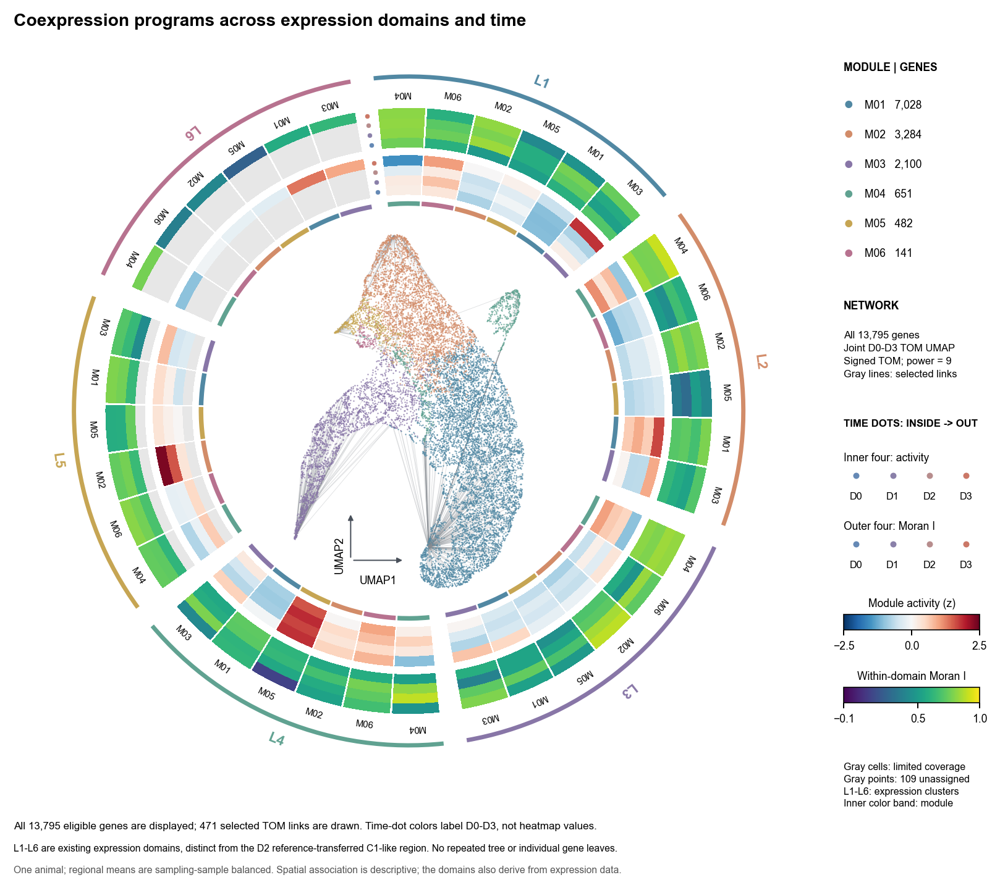

In [21]:
# 中文：图6m：绘制基因网络及区域和时间环图。
# English: Figure 6m: plot the gene network with regional and temporal rings.
style(7)
cfg={'selected_soft_power':9,'unassigned_genes':109,'network_genes':13795}
palette=['#5188A3','#D28C69','#8876A7','#60A291','#C6A553','#B7728F']
colors=dict(zip(mods,palette));colors['Unassigned']='#BDBDBD'
TCOL=['#6589B5','#8A80A9','#B78D8D','#CB7867']
def fig1():
 spot=spots
 rs=read('network_ring_reference.csv')
 nodes=read('network_nodes.csv.gz')
 edges=read('network_edges.csv')
 guide=read('network_ring_guide.csv')
 regions=[f'Cluster {i}' for i in range(1,7)];times=['D0','D1','D2','D3']
 tree=linkage(squareform(np.maximum(0,1-np.corrcoef(spot[mods].to_numpy().T)),checks=False),method='average')
 order=[mods[i] for i in leaves_list(tree)]
 fig=plt.figure(figsize=(9.4,8.1));ax=fig.add_axes([.018,.105,.79,.86]);ax.set_aspect('equal');ax.axis('off')
 ax.set_xlim(-1.27,1.27);ax.set_ylim(-1.27,1.27)
 fig.text(.035,.977,'Coexpression programs across expression domains and time',fontsize=11.3,weight='bold',va='top')
 actlim=float(np.ceil(np.nanmax(np.abs(rs.score_mean))*2)/2);anorm=Normalize(-actlim,actlim)
 low=min(-.1,float(np.floor(rs.Moran_I.min()*10)/10));high=max(.5,float(np.ceil(rs.Moran_I.max()*10)/10));inorm=Normalize(low,high)
 acmap=plt.get_cmap('RdBu_r');icmap=plt.get_cmap('viridis');lookup=rs.set_index(['expression_cluster','module','timepoint'])
 rcolors=['#5188A3','#D28C69','#8876A7','#60A291','#C6A553','#B7728F']
 radii=guide.inner_radius.tolist();width=.032;n=len(mods)
 for k,region in enumerate(regions):
  hi=96-60*k;lo=hi-56
  for j,m in enumerate(order):
   mh=hi-j*56/n;ml=mh-56/n;theta=(mh+ml)/2
   for it,tp in enumerate(times):
    q=lookup.loc[(region,m,tp)]
    for value,rad,cmap,norm in [(q.score_mean,radii[it],acmap,anorm),(q.Moran_I,radii[it+4],icmap,inorm)]:
     ax.add_patch(Wedge((0,0),rad+width,ml+.25,mh-.25,width=width,facecolor='#E7E7E7' if pd.isna(value) else cmap(norm(value)),edgecolor='none',linewidth=0,antialiased=False))
   ax.add_patch(Wedge((0,0),.688,ml+.25,mh-.25,width=.015,facecolor=colors[m],edgecolor='none'))
   rot=theta-90
   if 90<theta%360<270:rot+=180
   a=np.deg2rad(theta);ax.text(1.040*np.cos(a),1.040*np.sin(a),m,rotation=rot,rotation_mode='anchor',ha='center',va='center',fontsize=6)
  ax.add_patch(Wedge((0,0),1.104,lo,hi,width=.014,facecolor=rcolors[k],edgecolor='none'))
  a=np.deg2rad((lo+hi)/2);rot=(lo+hi)/2-90
  if 90<((lo+hi)/2)%360<270:rot+=180
  ax.text(1.162*np.cos(a),1.162*np.sin(a),'L'+str(k+1),rotation=rot,rotation_mode='anchor',ha='center',va='center',fontsize=9,weight='bold',color=rcolors[k])
 # Time dots in the opening identify each ring in the same way as the
 # condition markers in the reference layout; their colors are not values.
 marker_angle=np.deg2rad(98)
 for q in guide.itertuples():
  ax.scatter(q.marker_radius*np.cos(marker_angle),q.marker_radius*np.sin(marker_angle),s=11,c=q.time_marker_color,edgecolors='white',linewidths=.3,zorder=6)
 # Retain every original full-network gene coordinate; thin only the lines.
 xy=nodes[['UMAP1','UMAP2']].to_numpy();xy-=np.mean([xy.max(0),xy.min(0)],axis=0)
 xy*=.595/np.sqrt((xy*xy).sum(1)).max();index={g:i for i,g in enumerate(nodes.gene)}
 seg=[[xy[index[q.gene1]],xy[index[q.gene2]]] for q in edges.itertuples()]
 ax.add_collection(LineCollection(seg,colors='#858A90',linewidths=.35,alpha=.27,zorder=1))
 for m in ['Unassigned']+mods:
  ii=nodes.module.eq(m).to_numpy();ax.scatter(xy[ii,0],xy[ii,1],s=.8,c=colors[m],linewidths=0,alpha=.86,zorder=2)
 # Positive directions correspond to the untouched embedding's two axes.
 ox,oy=-.19,-.49
 ax.annotate('',xy=(ox+.18,oy),xytext=(ox,oy),arrowprops=dict(arrowstyle='-|>',color='#49505A',lw=.8,mutation_scale=7),zorder=8)
 ax.annotate('',xy=(ox,oy+.16),xytext=(ox,oy),arrowprops=dict(arrowstyle='-|>',color='#49505A',lw=.8,mutation_scale=7),zorder=8)
 ax.text(ox+.09,oy-.048,'UMAP1',fontsize=7,ha='center',va='top')
 ax.text(ox-.035,oy+.08,'UMAP2',fontsize=7,ha='right',va='center',rotation=90,rotation_mode='anchor')
 lx=.829;fig.text(lx,.913,'MODULE | GENES',fontsize=7,weight='bold')
 for j,q in module_summary.iterrows():
  y=.875-j*.033
  fig.text(lx,y,'\u25cf',fontsize=11,color=colors[q.module],va='center')
  fig.text(lx+.02,y,f'{q.module}   {int(q.n_genes):,}',fontsize=7,va='center')
 fig.text(lx,.648,'NETWORK',fontsize=7,weight='bold')
 fig.text(lx,.624,f'All {len(nodes):,} genes\nJoint D0-D3 TOM UMAP\nSigned TOM; power = {cfg["selected_soft_power"]}\nGray lines: selected links',fontsize=6.6,linespacing=1.5,va='top')
 fig.text(lx,.518,'TIME DOTS: INSIDE -> OUT',fontsize=6.7,weight='bold')
 for title,ty,dy in [('Inner four: activity',.489,.463),('Outer four: Moran I',.413,.387)]:
  fig.text(lx,ty,title,fontsize=7,va='top')
  for k,(tp,col) in enumerate(zip(TIMES,TCOL)):
   xx=lx+.012+k*.035
   fig.add_artist(Line2D([xx],[dy],marker='o',ms=4,color=col,markeredgewidth=0,linestyle='none',transform=fig.transFigure))
   fig.text(xx,dy-.018,tp,fontsize=6.5,ha='center',va='top')
 ca=fig.add_axes([lx,.292,.13,.017]);fig.colorbar(mpl.cm.ScalarMappable(norm=anorm,cmap=acmap),cax=ca,orientation='horizontal',ticks=[-actlim,0,actlim]);ca.set_title('Module activity (z)',fontsize=7,pad=5)
 ci=fig.add_axes([lx,.211,.13,.017]);fig.colorbar(mpl.cm.ScalarMappable(norm=inorm,cmap=icmap),cax=ci,orientation='horizontal',ticks=[low,.5,high]);ci.set_title('Within-domain Moran I',fontsize=7,pad=5)
 fig.text(lx,.145,f'Gray cells: limited coverage\nGray points: {cfg["unassigned_genes"]} unassigned\nL1-L6: expression clusters\nInner color band: module',fontsize=6.4,linespacing=1.4,va='top')
 fig.text(.035,.071,f'All {cfg["network_genes"]:,} eligible genes are displayed; {len(edges)} selected TOM links are drawn. Time-dot colors label D0-D3, not heatmap values.',fontsize=6.8)
 fig.text(.035,.046,'L1-L6 are existing expression domains, distinct from the D2 reference-transferred C1-like region. No repeated tree or individual gene leaves.',fontsize=6.3)
 fig.text(.035,.022,'One animal; regional means are sampling-sample balanced. Spatial association is descriptive; the domains also derive from expression data.',fontsize=6.3,color='#555555')
 finish(fig,'Fig1_network_cluster_module_time_Moran',axes=[ax])
fig1()


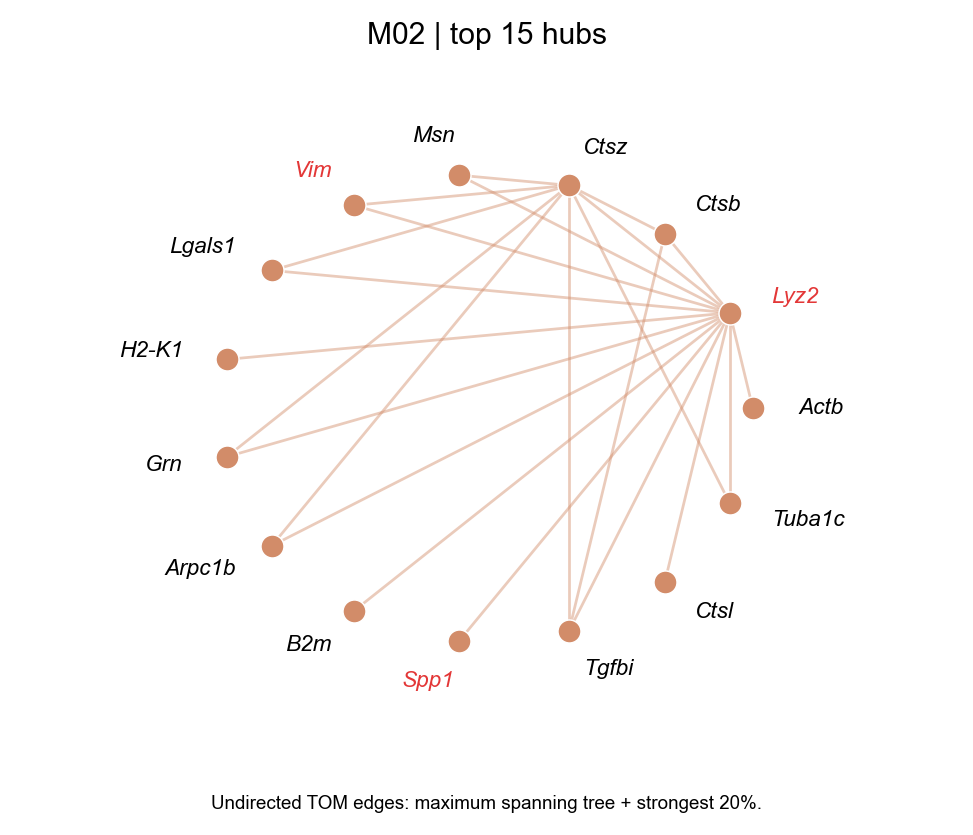

In [22]:
# 中文：图6n：从15个hub的全部TOM值构建M02展示网络。
# English: Figure 6n: construct the M02 display network from all TOM values among 15 hubs.
style(9)
hubs=read('M02_hub_nodes.csv');pairs=read('M02_hub_all_pair_TOM.csv')
assert len(hubs)==15 and len(pairs)==105
Gfull=nx.Graph();Gfull.add_nodes_from(hubs.gene)
for r in pairs.itertuples():Gfull.add_edge(r.gene1,r.gene2,weight=r.TOM)
backbone={frozenset(e) for e in nx.maximum_spanning_tree(Gfull).edges()}
cut=float(np.quantile(pairs.TOM,.8));G=nx.Graph();G.add_nodes_from(hubs.gene)
for r in pairs.itertuples():
    if r.TOM>=cut or frozenset([r.gene1,r.gene2]) in backbone:
        G.add_edge(r.gene1,r.gene2,weight=r.TOM)
pos=nx.circular_layout(G)
fig,ax=plt.subplots(figsize=(5.5,4.9));fig.subplots_adjust(left=.03,right=.97,bottom=.10,top=.87)
nx.draw_networkx_edges(G,pos,ax=ax,edge_color=colors['M02'],alpha=.45,width=1.1)
nx.draw_networkx_nodes(G,pos,ax=ax,node_size=85,node_color=colors['M02'],edgecolors='white',linewidths=.6)
for gene in hubs.gene:
    px,py=pos[gene]*1.17
    ax.text(px,py,gene,fontsize=9,ha='left' if px>=0 else 'right',va='center',fontstyle='italic',color='#e33737' if gene in CORE else 'black')
ax.set(xlim=(-1.75,1.75),ylim=(-1.45,1.45));ax.axis('off');ax.set_title('M02 | top 15 hubs',fontsize=12,pad=10)
fig.text(.5,.03,'Undirected TOM edges: maximum spanning tree + strongest 20%.',ha='center',fontsize=7.5)
render(fig,'Figure6n_M02_hubs',axes=[ax])


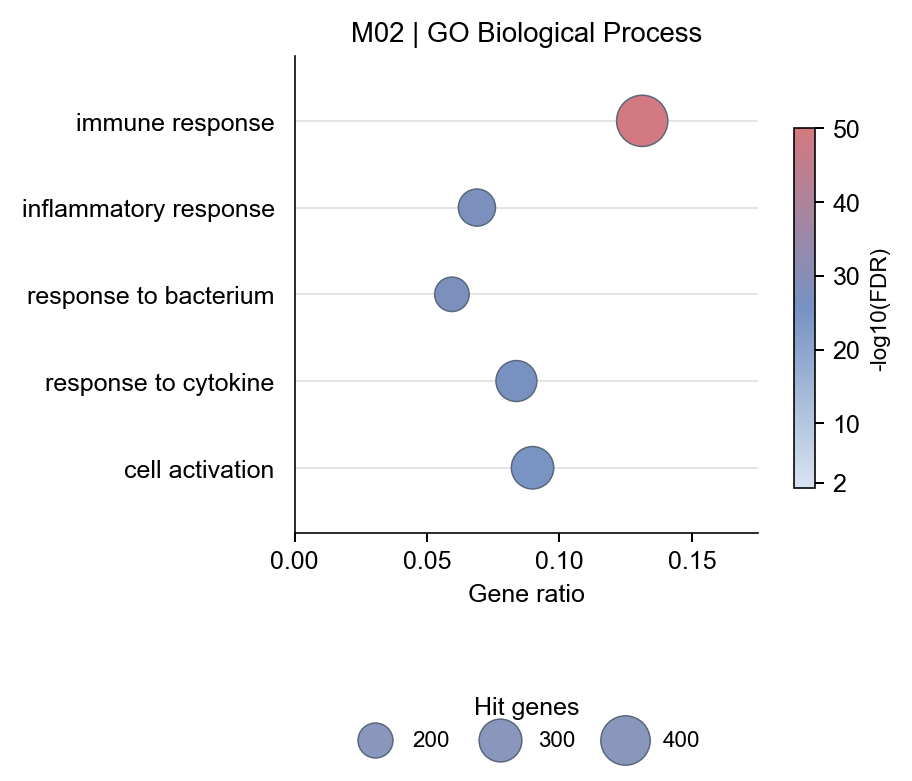

In [23]:
# 中文：图6n：在完整模块GO检验集合中校正并展示M02富集。
# English: Figure 6n: correct the full module GO test family and display M02 enrichment.
go=read('module_GO_statistics.csv.gz')
pv=hypergeom.sf(go.overlap.to_numpy()-1,go.background_genes,go.term_background_genes,go.module_mapped_genes)
assert np.allclose(pv,go.p_value,rtol=5e-8,atol=1e-300)
assert np.allclose(multipletests(go.p_value,method='fdr_bh')[1],go.FDR_global_BH,rtol=5e-8,atol=1e-300)
def choose_go(m):
 q=go[(go.module.eq(m))&(go.FDR_global_BH<.05)&(go.overlap>=3)].sort_values(['FDR_global_BH','overlap'],ascending=[True,False])
 # All module-term results are ranked by global FDR; no topic or pathway shortlist.
 chosen=[];sets=[]
 for row in q.itertuples():
  genes=set(str(row.overlap_genes).split(';'))
  if any(len(genes&s)/len(genes|s)>.5 for s in sets):continue
  chosen.append(row);sets.append(genes)
  if len(chosen)==5:break
 return pd.DataFrame(chosen)
q=choose_go('M02').sort_values(['FDR_global_BH','term_id']).reset_index(drop=True)
q['gene_ratio']=q.overlap/q.module_mapped_genes;q['minus_log10_FDR']=-np.log10(q.FDR_global_BH)
style(10)
fig,ax=plt.subplots(figsize=(6.6,5));fig.subplots_adjust(left=.43,right=.82,bottom=.30,top=.83)
cmap=LinearSegmentedColormap.from_list('blue_rose',['#d8e3f0','#7692C2','#D37980'])
norm=Normalize(-np.log10(.05),float(np.ceil(q.minus_log10_FDR.max())))
size=lambda n:420*np.asarray(n)/q.overlap.max()
ax.set_axisbelow(True);ax.grid(axis='y',color='#b2b7bd',linewidth=.65,alpha=.45)
ax.scatter(q.gene_ratio,np.arange(len(q)),s=size(q.overlap),c=q.minus_log10_FDR,cmap=cmap,norm=norm,edgecolors='#59677b',linewidths=.6,zorder=3)
ax.set_yticks(np.arange(len(q)),['\n'.join(textwrap.wrap(t,29)) for t in q.term_name]);ax.tick_params(axis='y',length=0,pad=8)
ax.set(ylim=(len(q)-.25,-.75),xlim=(0,float(np.ceil(q.gene_ratio.max()*1.18/.025)*.025)),xlabel='Gene ratio',title='M02 | GO Biological Process')
ax.xaxis.set_major_locator(MaxNLocator(4))
handles=[ax.scatter([],[],s=float(size(n)),facecolors='#8a97bd',edgecolors='#59677b',linewidths=.6,label=str(n)) for n in [200,300,400]]
ax.legend(handles=handles,title='Hit genes',loc='upper center',bbox_to_anchor=(.5,-.30),ncol=3,fontsize=9,handletextpad=.7,columnspacing=1.2)
cax=fig.add_axes([.85,.35,.018,.40]);cb=fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,ticks=[2,10,20,30,40,50]);cb.set_label('-log10(FDR)',fontsize=9)
render(fig,'Figure6n_M02_GO',axes=[ax])


## Extended Data Figure 3 — Spatial expression and enrichment / 空间表达与富集

English: Panel 3a uses the four gene maps above. The following panels show Ddn/Timp2 expression (3b), Moran's I for all 938 A-strong and 136 B-strong genes (3c), and GO Biological Process enrichment (3d).

中文：3a对应上方四基因空间图；以下展示Ddn/Timp2表达（3b）、938个A强变化和136个B强变化基因的Moran热图（3c），以及GO生物过程富集（3d）。


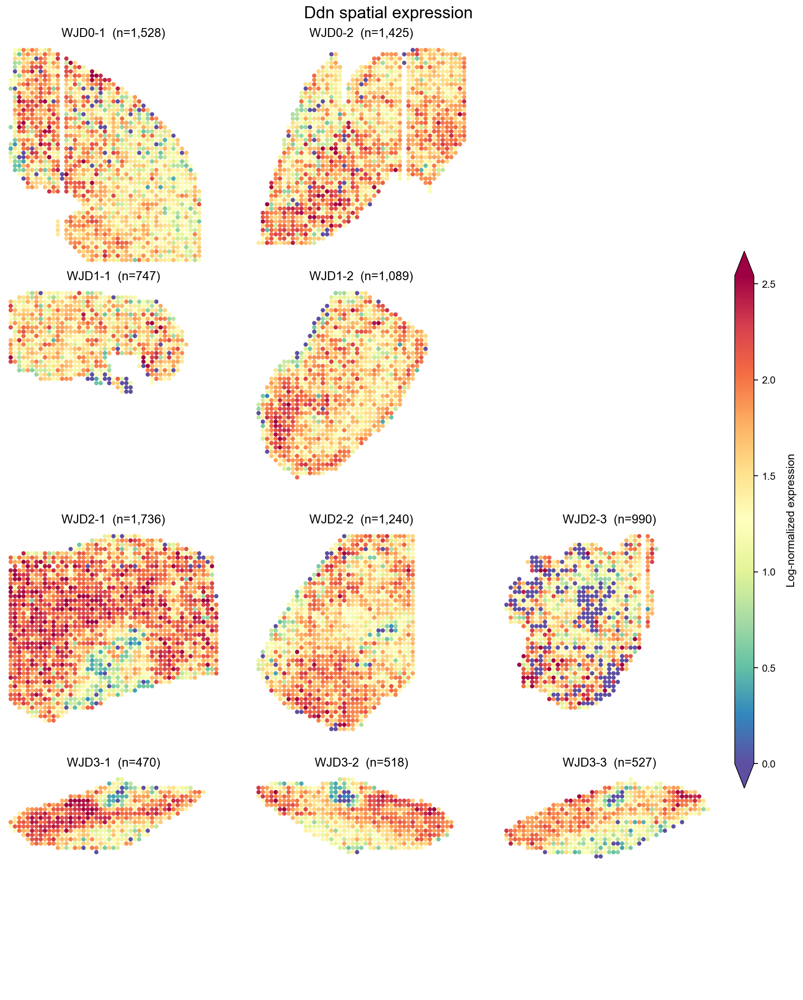

In [24]:
# 中文：扩展图3b：以共用1%–99%色标展示Ddn。
# English: Extended Data 3b: display Ddn with shared 1st–99th percentile limits.
plot_gene_map('Ddn')


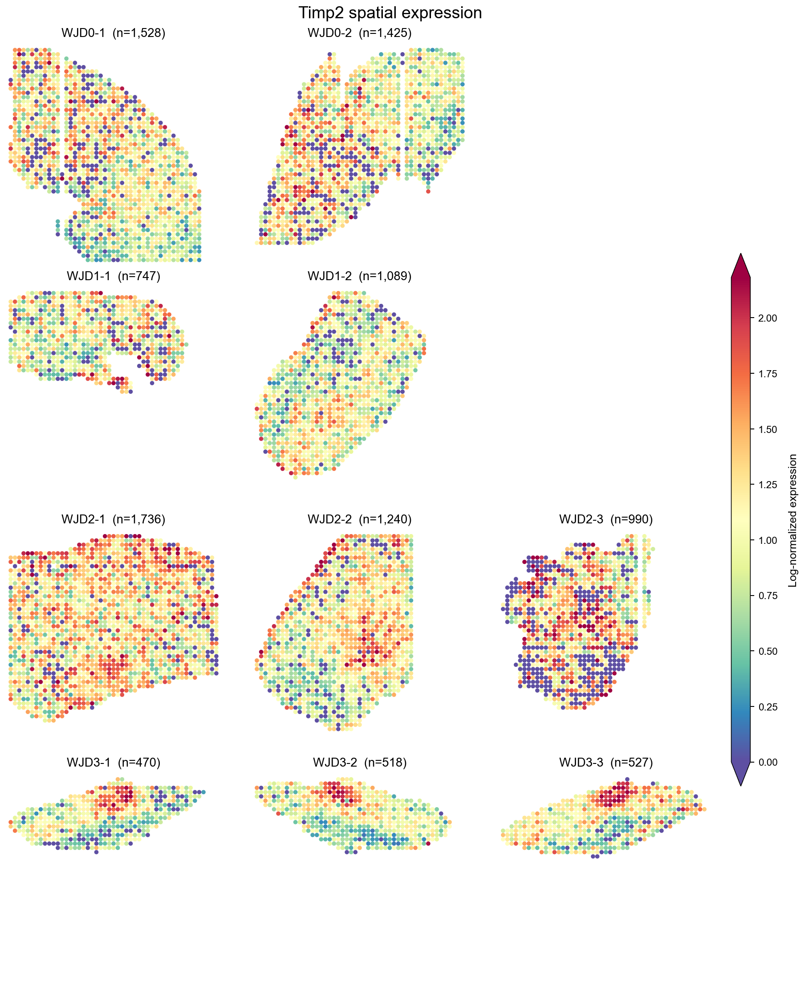

In [25]:
# 中文：扩展图3b：以共用1%–99%色标展示Timp2。
# English: Extended Data 3b: display Timp2 with shared 1st–99th percentile limits.
plot_gene_map('Timp2')


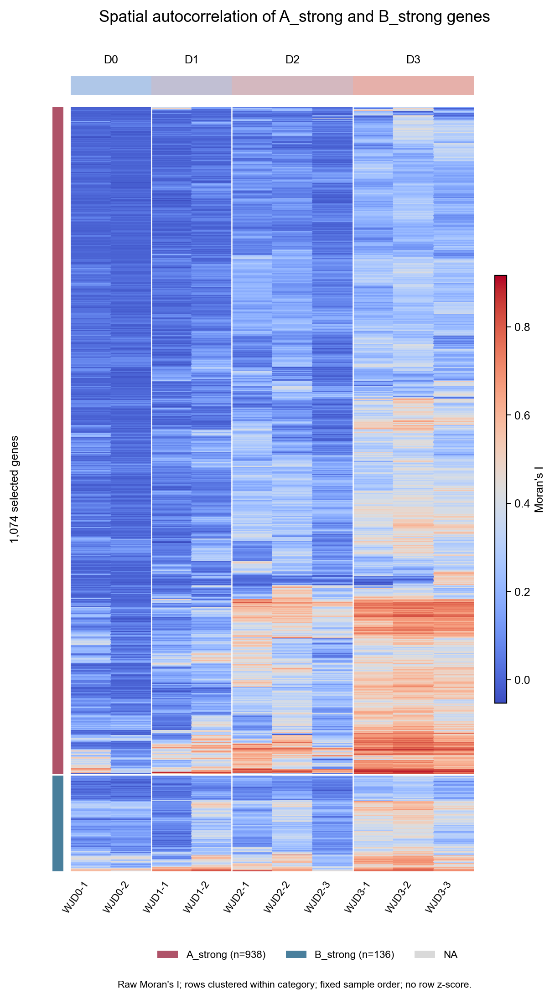

In [26]:
# 中文：扩展图3c：展示全部A/B强变化基因的Moran热图。
# English: Extended Data 3c: display Moran's I for all A/B-strong genes.
apply_style('heat')
render(gene_heatmap(matrix),'Extended3c_all_selected_Moran',axes=None)


In [27]:
# 中文：根据GO图谱与命中基因去冗余，每组选择八条展示条目。
# English: Select eight GO terms per group using graph and hit-set redundancy filters.
GO_FINAL_BROAD_NAMES = {
    'biological_process', 'biological regulation', 'regulation of biological process',
    'regulation of cellular process', 'positive regulation of biological process',
    'negative regulation of biological process', 'positive regulation of cellular process',
    'negative regulation of cellular process', 'cellular process',
    'multicellular organismal process', 'regulation of multicellular organismal process',
    'positive regulation of multicellular organismal process',
    'negative regulation of multicellular organismal process',
    'response to stimulus', 'regulation of response to stimulus',
    'positive regulation of response to stimulus', 'negative regulation of response to stimulus',
    'response to external stimulus', 'regulation of response to external stimulus',
    'positive regulation of response to external stimulus',
    'negative regulation of response to external stimulus',
    'immune system process', 'regulation of immune system process',
    'positive regulation of immune system process', 'negative regulation of immune system process',
    'immune effector process', 'regulation of defense response', 'regulation of immune response',
    'regulation of biological quality', 'signaling', 'cell communication',
    'regulation of cell communication', 'regulation of signaling',
    'cellular component organization', 'cellular component organization or biogenesis',
    'regulation of cellular component organization', 'negative regulation of cellular component organization',
    'regulation of cellular component biogenesis', 'positive regulation of cellular component biogenesis',
    'negative regulation of cellular component biogenesis',
    'localization', 'system process', 'nervous system process',
    'biological process involved in interspecies interaction between organisms',
    'response to external biotic stimulus', 'response to other organism',
    'response to biotic stimulus', 'defense response to symbiont',
    'defense response to other organism', 'regulation of multicellular organismal development',
    'positive regulation of cellular component organization',
    'defense response', 'immune response', 'response to chemical', 'response to stress',
    'response to peptide', 'locomotion', 'cell motility', 'cell activation',
    'cognition', 'behavior', 'learning or memory', 'learning', 'memory', 'long-term memory',
}
GO_FINAL_EXPOSURE_PATTERN = r'bacter|virus|viral|symbiont|biotic|other organism|lipopolysaccharide'

def select_go_final(table, parents, top_n=8):
    """Display refinement only; keep every original GO statistic untouched.

    Identical rules for A/B; no functional whitelist or manual selected GO IDs.
    Broad/exposure/behavior terms are display exclusions, not biological negatives.
    Prefer supported smaller descendants for near-identical hit sets (J>=0.8,
    adjusted P at most 100-fold parent P); then significance-first greedy J<0.6.
    """
    sig = table.loc[table.database.eq('GO:BP') & table.adjusted_p.lt(.05)].copy()
    sig = sig.sort_values(['adjusted_p', 'gene_count', 'term_id'], ascending=[True, False, True])
    audit = {r.term_id: {'name':r.term_name, 'decision':'eligible'} for r in sig.itertuples()}
    broad = sig.term_name.isin(GO_FINAL_BROAD_NAMES)
    exposure = sig.term_name.str.contains(GO_FINAL_EXPOSURE_PATTERN, case=False, regex=True)
    generic = sig.term_background_count.div(sig.background_count).gt(.10)
    for row in sig.itertuples():
        if row.term_name in GO_FINAL_BROAD_NAMES: audit[row.term_id]['decision'] = 'broad or phenotype-level display exclusion'
        elif bool(exposure.loc[row.Index]): audit[row.term_id]['decision'] = 'organism/exposure label; avoid infection inference'
        elif bool(generic.loc[row.Index]): audit[row.term_id]['decision'] = 'term covers >10% of effective GO background'
    candidates = sig.loc[~(broad | exposure | generic)].copy()
    rows = {r.term_id:r for r in candidates.itertuples()}
    hits = {k:set(filter(None, r.hit_ensembl_ids.split(';'))) for k,r in rows.items()}
    def ancestors(term):
        seen, stack = set(), list(parents.get(term, []))
        while stack:
            item = stack.pop()
            if item not in seen:
                seen.add(item); stack.extend(parents.get(item, []))
        return seen
    ancestor_sets = {k:ancestors(k) for k in rows}
    descendants = {}
    for child_id, child in rows.items():
        for parent_id in sorted(ancestor_sets[child_id] & rows.keys()):
            parent = rows[parent_id]
            jaccard = len(hits[child_id] & hits[parent_id]) / len(hits[child_id] | hits[parent_id])
            if (jaccard >= .8 and child.adjusted_p <= parent.adjusted_p * 100
                    and child.term_background_count < parent.term_background_count):
                descendants.setdefault(parent_id, []).append((child.adjusted_p, child.term_background_count, child_id, jaccard))
    for parent_id, choices in descendants.items():
        best = sorted(choices)[0]
        audit[parent_id].update(decision='near-identical supported smaller descendant', related=best[2], jaccard=best[3])
    selected = []
    for row in candidates.itertuples():
        if row.term_id in descendants: continue
        overlap = sorted([(len(hits[row.term_id] & hits[p]) / len(hits[row.term_id] | hits[p]), p)
                          for p in selected], reverse=True)
        if overlap and overlap[0][0] >= .6:
            audit[row.term_id].update(decision='hit-set redundancy J>=0.6', related=overlap[0][1], jaccard=overlap[0][0])
            continue
        if len(selected) == top_n:
            audit[row.term_id]['decision'] = 'outside significance-ranked first 8 representatives'
            continue
        selected.append(row.term_id); audit[row.term_id]['decision'] = 'selected'
    if len(selected) != top_n:
        raise ValueError(f'Only {len(selected)} significant GO representatives; do not relax P<0.05.')
    result = candidates.set_index('term_id').loc[selected].reset_index()
    result['display_order'] = np.arange(1, top_n+1)
    return result, audit, sig
links=read('GO_parent_links.csv.gz');parents=links.groupby('term_id',sort=False).parent_id.agg(list).to_dict()
full_go=read('gene_GO_statistics.csv.gz')
selected_go=[]
for category_ in ['A_strong','B_strong']:
    qgo=full_go[full_go.category.eq(category_)]
    assert qgo.query_size.eq(938 if category_=='A_strong' else 136).all()
    assert qgo.background_count.eq(18062).all()
    assert np.allclose(qgo.gene_ratio,qgo.gene_count/qgo.query_size)
    selected,_,_=select_go_final(qgo,parents);selected_go.append(selected)
GO_FINAL_SELECTED=pd.concat(selected_go,ignore_index=True)
display(GO_FINAL_SELECTED[['category','term_name','gene_count','adjusted_p']].reset_index(drop=True))


,category,term_name,gene_count,adjusted_p
0,A_strong,innate immune response,141,1.795662e-47
1,A_strong,inflammatory response,132,2.650795e-46
2,A_strong,cell migration,180,7.043333e-41
3,A_strong,response to cytokine,140,7.423915e-40
4,A_strong,regulation of cytokine production,111,1.688388e-33
5,A_strong,leukocyte activation,126,1.412556e-31
6,A_strong,chemotaxis,77,6.062699e-30
7,A_strong,positive regulation of defense response,86,5.723092e-29
8,B_strong,modulation of chemical synaptic transmission,24,3.925080e-12
9,B_strong,long-term synaptic potentiation,8,5.606750e-05


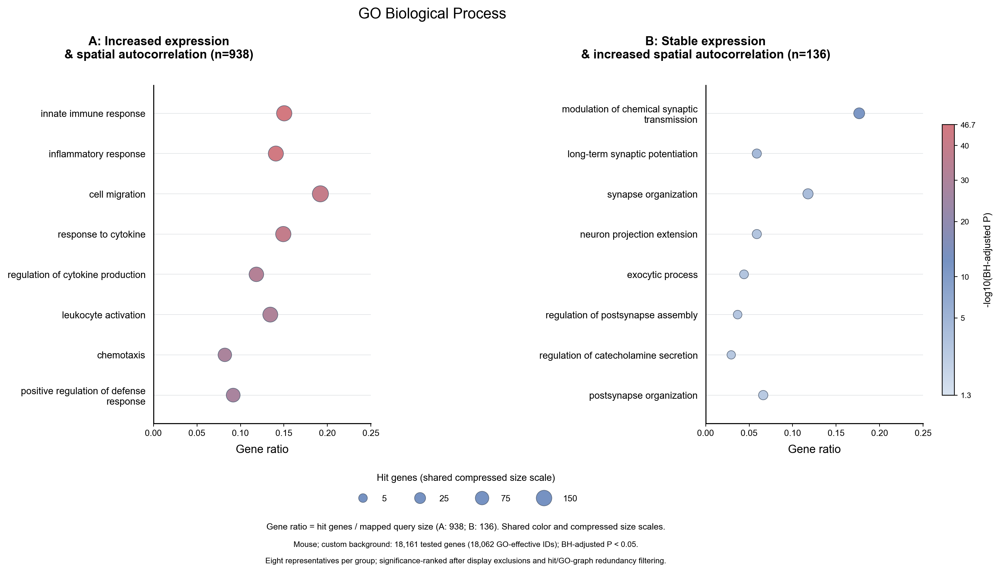

In [28]:
# 中文：扩展图3d：以共用色标和气泡面积规则展示GO富集。
# English: Extended Data 3d: plot GO enrichment with shared color and bubble-area scales.
def enrichment_bubble_area(hit_count):
    """Shared compressed marker area in pt²; count is read from the size legend.

    Preserve the previously agreed display rule so small B-group counts remain
    visible. The mapping is identical for A/B, monotonic and explicitly nonlinear.
    """
    return 50. + 22. * np.sqrt(np.asarray(hit_count, dtype=float))

def go_final_bubble_area(hit_count):
    """Common compressed display mapping; do not scale the groups separately."""
    return enrichment_bubble_area(hit_count)

def plot_fig6_10():
    final=GO_FINAL_SELECTED
    apply_style('heat')
    fig = plt.figure(figsize=(17.8,9.0))
    axs = [fig.add_axes([.25,.26,.195,.60]), fig.add_axes([.745,.26,.195,.60])]
    cmap = LinearSegmentedColormap.from_list('template_blue_rose', ['#d8e3f0','#7692C2','#D37980'])
    colors = -np.log10(final.adjusted_p.to_numpy(float))
    norm = PowerNorm(gamma=.5, vmin=-np.log10(.05), vmax=float(colors.max()))
    xmax = float(np.ceil(final.gene_ratio.max()*1.15/.05)*.05)
    titles = ['A: Increased expression\n& spatial autocorrelation (n=938)',
              'B: Stable expression\n& increased spatial autocorrelation (n=136)']
    for i,(ax,cat) in enumerate(zip(axs,['A_strong','B_strong'])):
        sub = final.loc[final.category.eq(cat)].sort_values('display_order')
        yy = np.arange(len(sub)); ax.set_axisbelow(True)
        ax.grid(axis='y', color='#b2b7bd', linewidth=.65, alpha=.4)
        dots = ax.scatter(sub.gene_ratio, yy, s=go_final_bubble_area(sub.gene_count),
            c=-np.log10(sub.adjusted_p), cmap=cmap, norm=norm,
            edgecolor='#59677b', linewidth=.65, alpha=1., rasterized=False)
        assert np.array_equal(dots.get_sizes(),50+22*np.sqrt(sub.gene_count.to_numpy(dtype=float)))
        assert np.array_equal(dots.get_array(),-np.log10(sub.adjusted_p.to_numpy()))
        ax.set_yticks(yy, ['\n'.join(textwrap.wrap(n,width=37)) for n in sub.term_name], fontsize=11)
        ax.set_ylim(len(sub)-.3,-.7); ax.set_xlim(0,xmax)
        ax.set_xticks(np.arange(0,xmax+.001,.05)); ax.tick_params(axis='x',labelsize=10)
        ax.set_xlabel('Gene ratio',fontsize=13,labelpad=8)
        ax.spines[['top','right']].set_visible(False); ax.tick_params(axis='y',length=0,pad=9)
        for side in ['left','bottom']:ax.spines[side].set_linewidth(1.15)
        fig.text([.255,.745][i],.925,titles[i],ha='center',va='center',fontsize=14,fontweight='bold')
    assert axs[0].get_xlim() == axs[1].get_xlim()
    fig.suptitle('GO Biological Process',y=.998,fontsize=17)
    counts = [5,25,75,150]
    handles = [Line2D([],[],marker='o',linestyle='',markersize=np.sqrt(go_final_bubble_area(k)),
                        markerfacecolor='#7692C2',markeredgecolor='#59677b',markeredgewidth=.65,label=str(k)) for k in counts]
    fig.legend(handles=handles,title='Hit genes (shared compressed size scale)',loc='lower center',bbox_to_anchor=(.53,.105),
               ncol=4,frameon=False,fontsize=10,title_fontsize=11,handletextpad=1.2,columnspacing=2.8,labelspacing=1.4)
    cax = fig.add_axes([.957,.31,.011,.48])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax)
    ticks = sorted(set([-np.log10(.05),5.,10.,20.,30.,40.,float(colors.max())]))
    ticks = [v for v in ticks if norm.vmin <= v <= norm.vmax]
    cb.set_ticks(ticks); cb.set_ticklabels([f'{v:.1f}' if v==ticks[0] or v==ticks[-1] else f'{v:g}' for v in ticks])
    cb.set_label('-log10(BH-adjusted P)',fontsize=11,labelpad=9); cb.ax.tick_params(labelsize=9)
    cb.solids.set_rasterized(False); cb.solids.set_edgecolor('face')
    fig.text(.53,.072,'Gene ratio = hit genes / mapped query size (A: 938; B: 136). Shared color and compressed size scales.',ha='center',fontsize=10)
    fig.text(.53,.041,'Mouse; custom background: 18,161 tested genes (18,062 GO-effective IDs); BH-adjusted P < 0.05.',ha='center',fontsize=9)
    fig.text(.53,.012,'Eight representatives per group; significance-ranked after display exclusions and hit/GO-graph redundancy filtering.',ha='center',fontsize=9)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    a_right = axs[0].get_window_extent(renderer).x1
    b_left = min(t.get_window_extent(renderer).x0 for t in axs[1].get_yticklabels())
    assert a_right + 10 < b_left, 'A data overlap B GO labels'
    for ax in axs:
        boxes = sorted([t.get_window_extent(renderer) for t in ax.get_yticklabels()],key=lambda b:b.y0)
        assert all(one.y1+2 < two.y0 for one,two in zip(boxes,boxes[1:])), 'GO labels overlap vertically'
    render(fig,'Extended3d_AB_GO',axes=axs)

plot_fig6_10()


## Extended Data Figure 4 — Cell classes and distance profiles / 细胞类别与距离分布

English: Six-class spatial RCTD maps are followed by distance-band RNA composition, single-cell reference expression, the M02/C1 boundary map and M02 distance means. The SCC H&E is shown in the Figure 6b section.

中文：依次展示六类细胞的RCTD空间图、距离分组RNA组成、单细胞参考表达、M02/C1边界图及M02距离均值。SCC的H&E位于图6b部分。


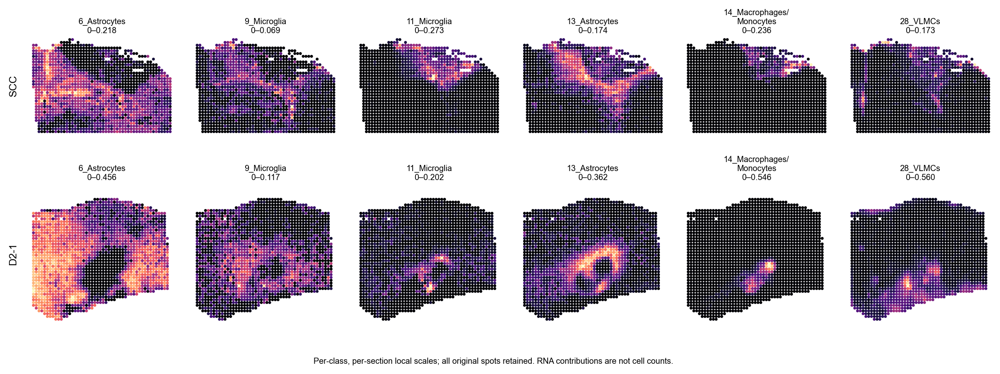

In [29]:
# 中文：扩展图4a/b：展示参考切片与D2中六类细胞的RNA权重。
# English: Extended Data 4a/b: display six-class RNA weights in the reference and D2 sections.
style(8)
selected_types=['6_Astrocytes','9_Microglia','11_Microglia','13_Astrocytes','14_Macrophages_Monocytes','28_VLMCs']
fig,axs=plt.subplots(2,6,figsize=(13.8,5.6));fig.subplots_adjust(left=.045,right=.99,bottom=.13,top=.88,wspace=.15,hspace=.19)
for ri,(sample,meta,weights,ylim) in enumerate([('SCC',w,W,(0,35)),('D2-1',d,DW,(50.5,.5))]):
    for ci,c in enumerate(selected_types):
        ax=axs[ri,ci];vmax=float(weights[c].max())
        coll=EllipseCollection(np.full(len(meta),1.03),np.full(len(meta),1.03),np.zeros(len(meta)),units='xy',offsets=meta[['x','y']].to_numpy(),offset_transform=ax.transData,cmap='magma',norm=Normalize(0,vmax),edgecolors='none')
        coll.set_array(weights[c].to_numpy());ax.add_collection(coll)
        ax.set(xlim=(0,51),ylim=ylim,aspect='equal');ax.axis('off')
        ax.set_title(type_title(c)+f'\n0–{vmax:.3f}',fontsize=8,pad=4)
    axs[ri,0].text(-.12,.5,sample,transform=axs[ri,0].transAxes,rotation=90,va='center',ha='center',fontsize=10)
fig.text(.5,.035,'Per-class, per-section local scales; all original spots retained. RNA contributions are not cell counts.',ha='center',fontsize=8)
render(fig,'Extended4ab_six_RCTD_classes',axes=list(axs.flat))


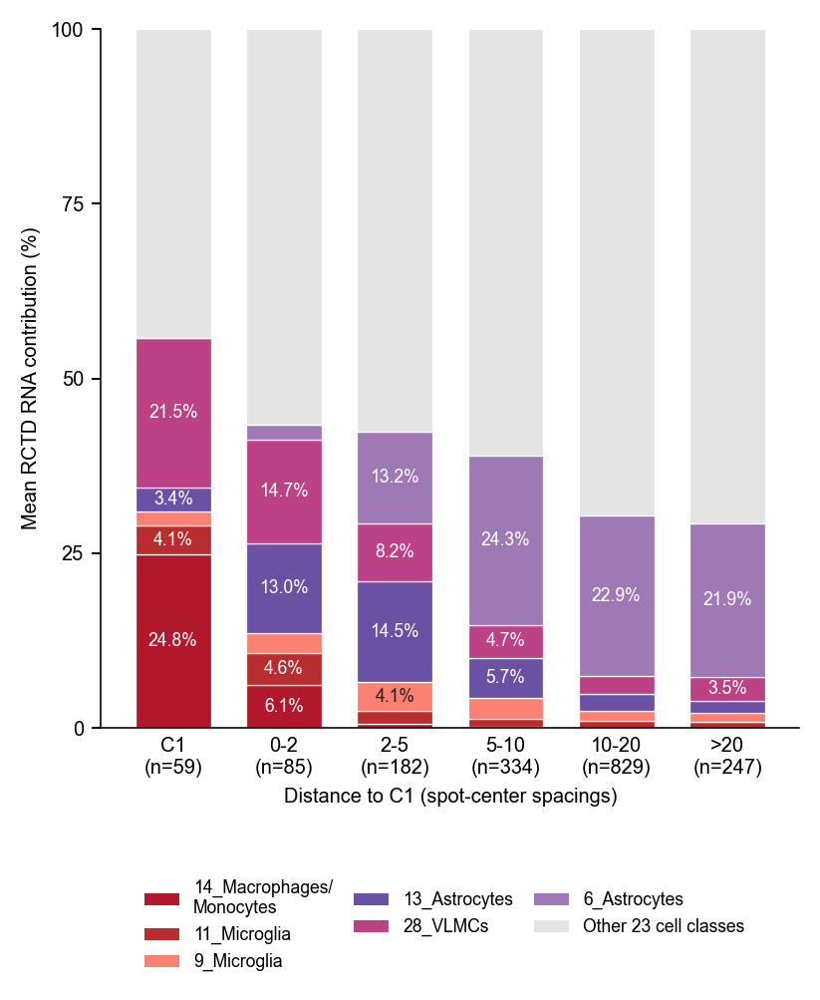

In [30]:
# 中文：扩展图4d：完整29类为分母，绘制六类加其余23类的100%堆叠图。
# English: Extended Data 4d: draw six classes plus the other 23 with the full 29-class denominator.
style(8)
composition=profile_rctd.loc[focus].copy();composition.loc['Other23']=profile_rctd.drop(index=focus).sum(axis=0)
assert np.allclose(composition.sum(axis=0),100)
fig,ax=plt.subplots(figsize=(6.4,5.9));fig.subplots_adjust(left=.14,right=.97,bottom=.28,top=.94);ax.set_box_aspect(1)
bottom=np.zeros(6);handles=[]
for c in focus+['Other23']:
    value=composition.loc[c].to_numpy();color='#e4e4e4' if c=='Other23' else col(c)
    ax.bar(range(6),value,bottom=bottom,width=.68,color=color,edgecolor='white',linewidth=.5)
    if c!='Other23':
        rgb=mpl.colors.to_rgb(color);lum=np.dot(rgb,[.2126,.7152,.0722])
        for j,v in enumerate(value):
            if v>=3:ax.text(j,bottom[j]+v/2,f'{v:.1f}%',ha='center',va='center',fontsize=7,color='#222222' if lum>.55 else 'white')
    handles.append(Patch(facecolor=color,label='Other 23 cell classes' if c=='Other23' else type_title(c)));bottom+=value
ax.set(ylim=(0,100),xlim=(-.65,5.65),yticks=[0,25,50,75,100],ylabel='Mean RCTD RNA contribution (%)',xlabel='Distance to C1 (spot-center spacings)')
ax.set_xticks(range(6),[f'{b}\n(n={int(band_counts[b])})' for b in bands]);ax.tick_params(axis='x',length=0)
fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.55,.035),ncol=3,fontsize=7,columnspacing=1.2)
render(fig,'Extended4d_distance_composition',axes=[ax])


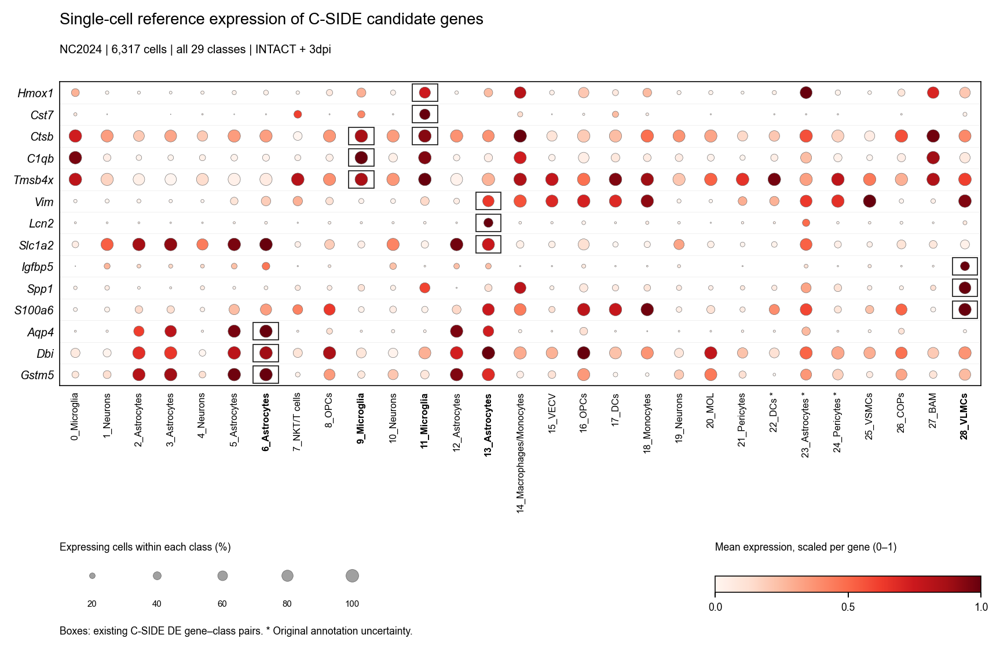

In [31]:
# 中文：扩展图4e：用6317个参考细胞原UMI及完整文库总数重算均值和检测比例。
# English: Extended Data 4e: recompute expression means and detection fractions from 6,317 reference cells with full-library UMI totals.
selected=read('CSIDE_selected_genes.csv');ref_genes=selected.drop_duplicates('gene_id')
rc=read('NC2024_candidate_raw_counts.csv.gz')
assert len(rc)==6317 and len(ref_genes)==14
labels_ref=rc.rctd_cell_type.to_numpy();raw_ref=rc[ref_genes.gene_symbol].to_numpy(float)
expr_ref=np.log1p(raw_ref*10000/rc.full_library_UMI.to_numpy()[:,None])
mean=np.stack([expr_ref[labels_ref==t].mean(axis=0) for t in types])
fraction=np.stack([(raw_ref[labels_ref==t]>0).mean(axis=0) for t in types])
lo,hi=mean.min(axis=0),mean.max(axis=0);scaled=np.divide(mean-lo,hi-lo,out=np.zeros_like(mean),where=(hi-lo)>0)
highlighted=set(zip(selected.cell_type,selected.gene_symbol));focus_ref=set(selected.cell_type)
uncertain=set(rc.loc[rc.annotation_confidence.ne('HIGH'),'rctd_cell_type'])
style(7)
fig=plt.figure(figsize=(10.4,6.2));ax=fig.add_axes([.095,.40,.85,.47])
xx,yy=np.meshgrid(np.arange(29),np.arange(14));largest_dot=76.
scat=ax.scatter(xx.ravel(),yy.ravel(),s=(fraction.T*largest_dot).ravel(),c=scaled.T.ravel(),cmap='Reds',vmin=0,vmax=1,edgecolors='#666666',linewidths=.25,zorder=3)
ax.set(xlim=(-.5,28.5),ylim=(13.5,-.5))
names=[type_title(t).replace('\n','')+(' *' if t in uncertain else '') for t in types]
ax.set_xticks(np.arange(29),names,rotation=90,ha='right',va='center',rotation_mode='anchor',fontsize=6.5)
ax.set_yticks(np.arange(14),ref_genes.gene_symbol,fontsize=8,fontstyle='italic');ax.tick_params(axis='both',length=0,pad=4)
for txt,t in zip(ax.get_xticklabels(),types):
    if t in focus_ref:txt.set_fontweight('bold')
for y_ in np.arange(.5,13.5):ax.axhline(y_,color='#eeeeee',lw=.35,zorder=0)
for i,t in enumerate(types):
    for j,g in enumerate(ref_genes.gene_symbol):
        if (t,g) in highlighted:ax.add_patch(Rectangle((i-.4,j-.4),.8,.8,facecolor='none',edgecolor='#202020',lw=.7,zorder=4))
for sp in ax.spines.values():sp.set_visible(True)
fig.text(.095,.96,'Single-cell reference expression of C-SIDE candidate genes',fontsize=11)
fig.text(.095,.915,'NC2024 | 6,317 cells | all 29 classes | INTACT + 3dpi',fontsize=8)
legend_ax=fig.add_axes([.095,.07,.30,.055]);legend_ax.set(xlim=(0,5),ylim=(0,1));legend_ax.axis('off')
for j,f in enumerate([.2,.4,.6,.8,1.]):
    legend_ax.scatter(j+.5,.65,s=f*largest_dot,c='#a0a0a0',edgecolors='#666666',linewidths=.3)
    legend_ax.text(j+.5,-.03,str(int(f*100)),ha='center',va='top',fontsize=6)
fig.text(.095,.145,'Expressing cells within each class (%)',fontsize=7)
cax=fig.add_axes([.70,.08,.245,.025]);fig.colorbar(scat,cax=cax,orientation='horizontal',ticks=[0,.5,1])
fig.text(.70,.145,'Mean expression, scaled per gene (0–1)',fontsize=7)
fig.text(.095,.015,'Boxes: existing C-SIDE DE gene–class pairs. * Original annotation uncertainty.',fontsize=7)
render(fig,'Extended4e_reference_expression',axes=[ax])


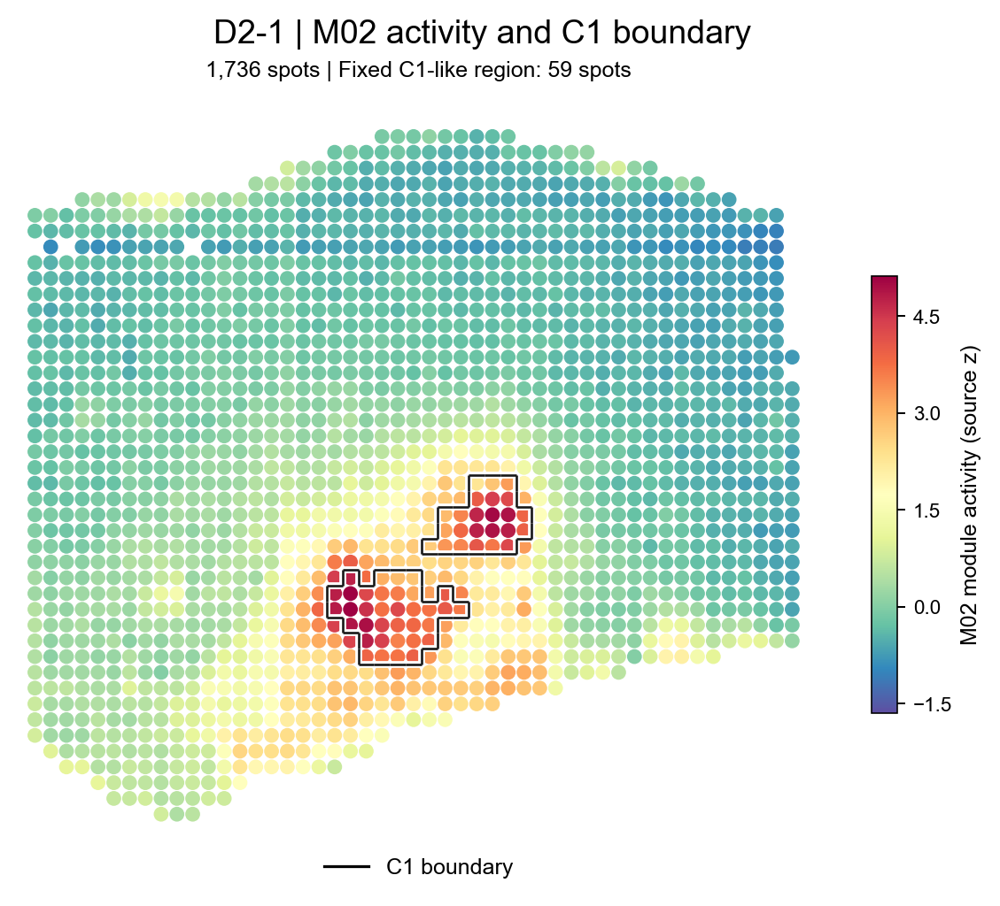

In [32]:
# 中文：扩展图4f：在M02活性图上叠加59个C1网格单元的边界。
# English: Extended Data 4f: overlay the boundary of 59 C1 grid cells on M02 activity.
d2=spots[spots.sample_name.eq('WJD2-1')].merge(d[['x','y','is_C1','distance_grid_pitch','distance_band','C1_proximity']],on=['x','y'],how='inner',validate='one_to_one')
assert len(d2)==1736 and d2.is_C1.sum()==59
style(9)
fig=plt.figure(figsize=(6.6,6.1));ax=fig.add_axes([.06,.13,.75,.73])
module_norm=Normalize(float(spots.M02.min()),float(spots.M02.max()))
marks=EllipseCollection(np.full(len(d2),.94),np.full(len(d2),.94),np.zeros(len(d2)),units='xy',offsets=d2[['plot_x','plot_y']].to_numpy(),offset_transform=ax.transData,cmap='Spectral_r',norm=module_norm,edgecolors='none')
marks.set_array(d2.M02.to_numpy());ax.add_collection(marks)
boundary=set()
for x_,y_ in d2.loc[d2.is_C1,['plot_x','plot_y']].to_numpy():
    corners=[(x_-.5,y_-.5),(x_+.5,y_-.5),(x_+.5,y_+.5),(x_-.5,y_+.5)]
    for i in range(4):
        edge=tuple(sorted([corners[i],corners[(i+1)%4]]))
        if edge in boundary:boundary.remove(edge)
        else:boundary.add(edge)
segments=np.asarray(sorted(boundary))
ax.add_collection(LineCollection(segments,colors='white',linewidths=3.1,zorder=4))
ax.add_collection(LineCollection(segments,colors='#171717',linewidths=1.05,zorder=5))
ax.set(xlim=(d2.plot_x.min()-1,d2.plot_x.max()+1),ylim=(d2.plot_y.max()+1,d2.plot_y.min()-1),aspect='equal');ax.axis('off')
fig.suptitle('D2-1 | M02 activity and C1 boundary',fontsize=15,y=.965)
fig.text(.44,.905,'1,736 spots | Fixed C1-like region: 59 spots',ha='center',fontsize=10)
cax=fig.add_axes([.87,.25,.025,.45]);cb=fig.colorbar(mpl.cm.ScalarMappable(norm=module_norm,cmap='Spectral_r'),cax=cax)
cb.set_label('M02 module activity (source z)',fontsize=10);cb.ax.yaxis.set_major_locator(MaxNLocator(6))
fig.legend(handles=[Line2D([],[],color='black',lw=1.3,label='C1 boundary')],loc='lower center',bbox_to_anchor=(.44,.06),fontsize=10)
render(fig,'Extended4f_M02_C1_boundary',axes=[ax])


,n_spots,M02
distance_band,,
C1,59,3.965257
0-2,85,2.557217
2-5,182,1.468589
5-10,334,0.453310
10-20,829,-0.124741
>20,247,-0.276860


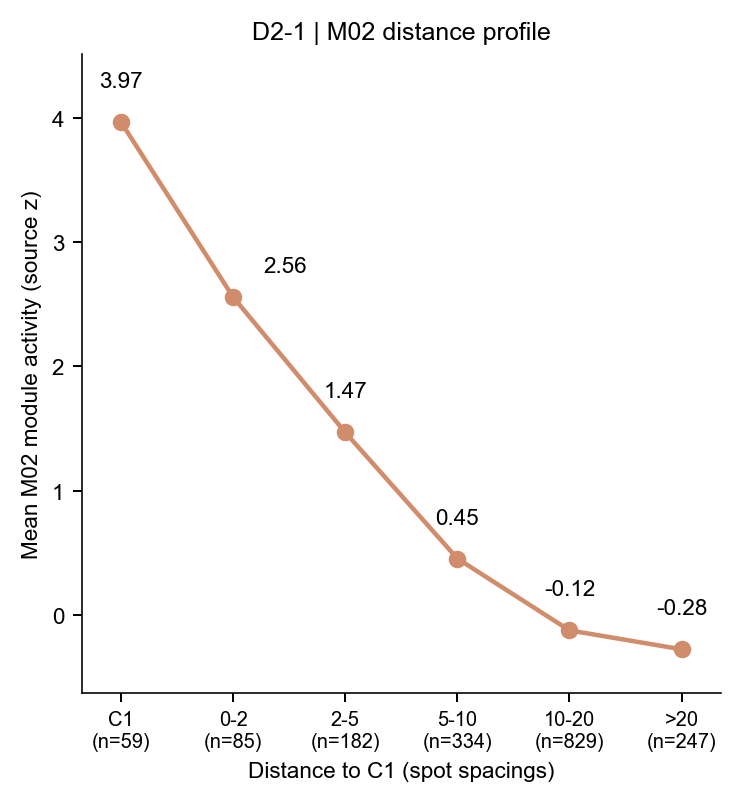

In [33]:
# 中文：扩展图4g：计算六个距离区间的M02平均活性。
# English: Extended Data 4g: calculate mean M02 activity in six distance bands.
profile=d2.groupby('distance_band',observed=True).agg(n_spots=('M02','size'),M02=('M02','mean')).reindex(bands)
assert profile.n_spots.tolist()==[59,85,182,334,829,247]
style(9)
fig,ax=plt.subplots(figsize=(5.6,5.3));fig.subplots_adjust(left=.17,right=.97,bottom=.20,top=.87);ax.set_box_aspect(1)
v=profile.M02.to_numpy();ax.plot(np.arange(6),v,color='#D18C6B',marker='o',ms=6,lw=1.8)
ax.set_xticks(np.arange(6),[f'{b}\n(n={n})' for b,n in zip(bands,profile.n_spots)],fontsize=8)
ax.set(xlim=(-.35,5.35),ylim=(v.min()-.35,v.max()+.55),ylabel='Mean M02 module activity (source z)',xlabel='Distance to C1 (spot spacings)',title='D2-1 | M02 distance profile')
for j,value in enumerate(v):
    offset=(12,10) if j==1 else (0,14)
    ax.annotate(f'{value:.2f}',(j,value),xytext=offset,textcoords='offset points',ha='left' if j==1 else 'center',fontsize=9)
display(profile)
render(fig,'Extended4g_M02_distance_profile',axes=[ax])


## Supplementary Figure S11 — M02 spatial activity / M02空间活性

English: M02 activity across all ten captures, using native spatial positions and a common color scale shared with the D2 C1-boundary map.

中文：展示全部十次采样的M02活性，使用原生空间位置，并与D2的C1边界图共用色标。


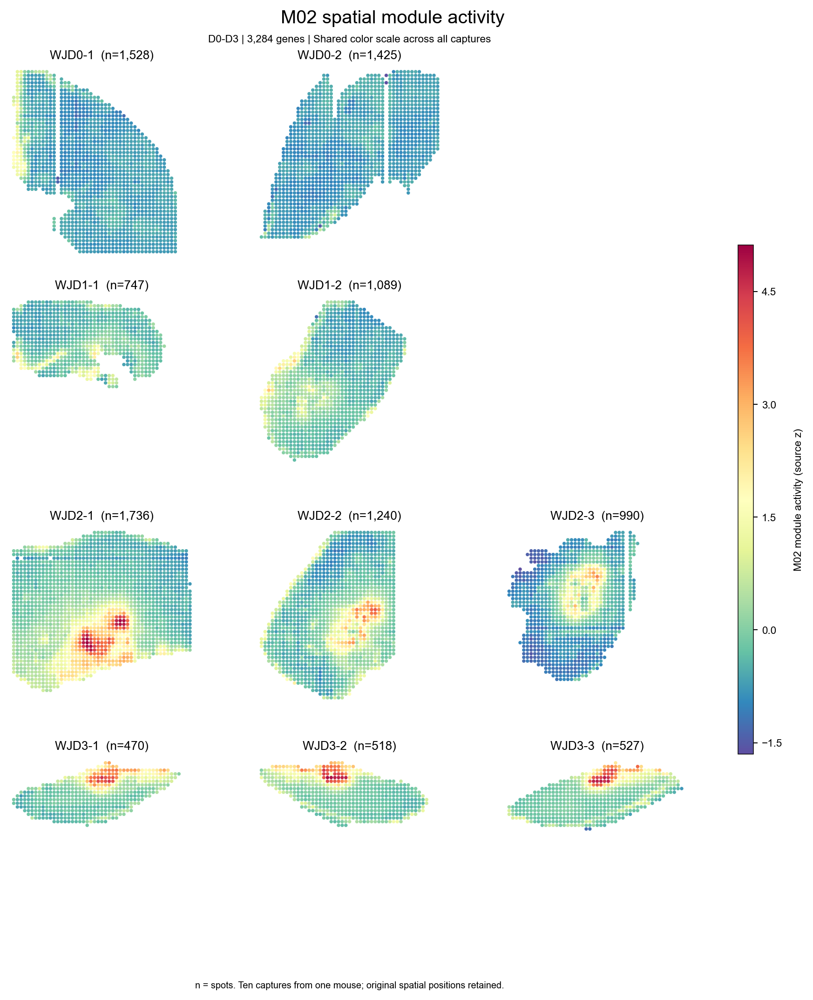

In [34]:
# 中文：补充图S11：按4×3布局展示十次采样的M02活性。
# English: Supplementary S11: show M02 activity across ten captures in a 4×3 layout.
def plot_spatial(spots,qa):
    # Arrange four day rows with up to three captures per row and a shared color map.
    fig,axes=plt.subplots(4,3,figsize=(10.3,12.4))
    fig.subplots_adjust(left=.035,right=.865,bottom=.065,top=.91,wspace=.12,hspace=.23)
    xmax=float(spots.plot_x.max());ymax=float(spots.plot_y.max())
    norm=Normalize(*qa['spatial_range'])
    active=[];ids=[];row_groups=[]
    for ri,day in enumerate(['D0','D1','D2','D3']):
        dayids=[]
        for ci,ax in enumerate(axes[ri]):
            names=[s for s in SAMPLES if s.startswith('WJ'+day+'-')]
            if ci>=len(names): ax.set_visible(False);continue
            sample=names[ci];g=spots.loc[spots.sample_name.eq(sample)]
            coll=EllipseCollection(np.full(len(g),.94),np.full(len(g),.94),np.zeros(len(g)),
                units='xy',offsets=g[['plot_x','plot_y']].to_numpy(),offset_transform=ax.transData,
                cmap='Spectral_r',norm=norm,edgecolors='none',linewidths=0,rasterized=False)
            coll.set_array(g.M02.to_numpy());ax.add_collection(coll)
            ax.set(xlim=(-1,xmax+1),ylim=(ymax+1,-1),aspect='equal')
            ax.set_axis_off();ax.set_title(f'{sample}  (n={len(g):,})',fontsize=10.5,pad=8)
            active.append(ax);ids.append(sample);dayids.append(sample)
        row_groups.append(dayids)
    fig.suptitle('M02 spatial module activity',fontsize=16,y=.966)
    fig.text(.45,.935,'D0-D3 | 3,284 genes | Shared color scale across all captures',ha='center',fontsize=9)
    cax=fig.add_axes([.9,.25,.018,.49])
    cb=fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap='Spectral_r'),cax=cax)
    cb.set_label('M02 module activity (source z)',labelpad=10)
    cb.ax.yaxis.set_major_locator(MaxNLocator(6));cb.outline.set_linewidth(.6)
    fig.text(.45,.025,'n = spots. Ten captures from one mouse; original spatial positions retained.',ha='center',fontsize=8)

    render(fig,'S11_M02_all_10_samples',axes=active)
style(9)
plot_spatial(spots,{'spatial_range':[float(spots.M02.min()),float(spots.M02.max())]})


## Software versions / 软件版本

English: Package versions for the current notebook session.

中文：当前notebook会话使用的软件包版本。


In [35]:
# 中文：显示本次分析使用的软件包版本。
# English: Display package versions used in this analysis.
assert sha256(INPUT_H5AD)==INPUT_SHA256
assert len(table)==18161 and len(nodes)==13795 and len(spots)==10270
packages = ['anndata', 'scanpy', 'numpy', 'pandas', 'scipy', 'matplotlib', 'networkx', 'statsmodels']
display(pd.DataFrame({'Package': packages, 'Version': [importlib.metadata.version(p) for p in packages]}))


,Package,Version
0,anndata,0.11.4
1,scanpy,1.11.5
2,numpy,2.2.6
3,pandas,2.3.3
4,scipy,1.15.3
5,matplotlib,3.10.8
6,networkx,3.4.2
7,statsmodels,0.14.6
